# I10 — Diffusion-Based Image Restoration on DIV2K

**Project:** I10 · Image Projects · **Dataset:** DIV2K (2K-resolution natural images) · **Runtime target:** Google Colab, NVIDIA T4

This notebook builds and evaluates a full image-restoration pipeline that removes a **combined degradation** (Gaussian blur + Gaussian noise + JPEG compression) from DIV2K images. It compares a classic conditional diffusion baseline against an improved **hybrid residual-diffusion** model (CNN + Swin-Transformer, ImageNet-pretrained conditioning, few-step DDIM sampling), and ends with an interactive Gradio demo.

### Key Performance Indicators (KPIs)

| KPI | Target | Measured on |
|---|---|---|
| PSNR (RGB) | **≥ 28 dB** | 100 DIV2K validation images, full resolution, *medium* degradation preset (blur 1.0, noise 12, JPEG 75) |
| SSIM (RGB) | **≥ 0.85** | same |
| LPIPS (AlexNet) | **≤ 0.20** | same |
| Efficiency | **≥ 10 % latency reduction _or_ ≥ 1 dB PSNR gain** vs. the diffusion baseline B0 | same, GPU latency per image |

### Table of contents
0. Setup — packages, Google Drive persistence, configuration, experiment tracking
1. Problem statement, literature review, dataset survey *(Deliverable 1)*
2. Data acquisition, cleaning, degradation synthesis, EDA *(Deliverable 2)*
3. Shared building blocks — metrics, tiled inference, network blocks, diffusion, training loop
4. Baselines R0 and B0 *(Deliverable 3)*
5. Final model F1 + KPI check + ablation study *(Deliverable 4)*
6. Diagnostics and plots *(Deliverable 5)*
7. Interactive Gradio demo *(Deliverable 6)*
8. Technical report, README, demo and presentation guide *(Deliverables 5 & 6)*

### How to run
1. **Runtime ▸ Change runtime type ▸ T4 GPU.**
2. In cell **0.4**, choose the run mode: `FAST_MODE = True` runs a **< 5 min smoke test** (the scores are not meaningful); `FAST_MODE = False` runs the **full first-review pipeline (~45–55 min on a T4)**.
3. **Runtime ▸ Run all.** Allow Google Drive access when asked. Everything (downloads, caches, checkpoints, CSV logs, figures) is stored in `MyDrive/I10_DIV2K/`. If the runtime disconnects, run all cells again: finished work is reloaded and unfinished training resumes from its last checkpoint.

| Section | Approx. T4 time (first full run) | Re-run with cache |
|---|---|---|
| 0 Setup | ~1.5 min | ~0.5 min |
| 2 Data + EDA | ~7 min | ~1 min |
| 4 Baselines | ~15 min | ~0.5 min |
| 5 Final model + ablation | ~22 min | ~1 min |
| 6–7 Diagnostics + demo | ~2 min | ~2 min |

In [1]:
# ── 0.2  Install missing packages & check the GPU ───────────────────────────────
import importlib.util, subprocess, sys

REQUIRED = {                      # import name -> pip specifier
    "lpips": "lpips",
    "gradio": "gradio>=4.44,<6",
    "timm": "timm",
    "albumentations": "albumentations",
    "skimage": "scikit-image",
    "cv2": "opencv-python-headless",
    "wandb": "wandb",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "requests": "requests",
    "tqdm": "tqdm",
}
missing = [spec for mod, spec in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

import torch
if torch.cuda.is_available():
    _p = torch.cuda.get_device_properties(0)
    print(f"GPU : {_p.name}  |  {_p.total_memory / 1024**3:.1f} GB  |  CUDA {torch.version.cuda}  |  torch {torch.__version__}")
    if "T4" not in _p.name:
        print("Note: training budgets are calibrated for a T4; other GPUs simply finish faster or slower.")
else:
    print("WARNING: no GPU detected. In Colab use Runtime > Change runtime type > T4 GPU, then run all cells again.\n"
          "The notebook still runs on CPU, but every time budget will be far exceeded.")

All required packages are already installed.
GPU : NVIDIA GeForce RTX 5060 Ti  |  15.9 GB  |  CUDA 12.8  |  torch 2.11.0+cu128
Note: training budgets are calibrated for a T4; other GPUs simply finish faster or slower.


In [2]:
# ── 0.3  Imports, versions, seeds, plotting style ──────────────────────────────
import os, io, gc, re, json, math, time, random, shutil, zipfile, hashlib, warnings, zlib
import importlib.util
from pathlib import Path
from dataclasses import dataclass, field, asdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import requests
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, get_worker_info

import albumentations as A
import timm
import lpips
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
MODEL_COLORS = {"Degraded": "#9aa0a6", "R0": "#4c78a8", "B0": "#f58518", "F1": "#54a24b"}

print(pd.DataFrame({
    "package": ["python", "torch", "timm", "albumentations", "opencv", "numpy", "pandas"],
    "version": [sys.version.split()[0], torch.__version__, timm.__version__, A.__version__,
                cv2.__version__, np.__version__, pd.__version__],
}).to_string(index=False))
print("device:", DEVICE)

c:\Users\Intel\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


       package      version
        python      3.10.11
         torch 2.11.0+cu128
          timm       1.0.31
albumentations        2.0.8
        opencv        5.1.0
         numpy        2.2.6
        pandas        2.3.3
device: cuda


In [3]:
# ── 0.4  Run mode + Google Drive persistence (automatic local fallback) ────────
FAST_MODE = False   # True = < 5 min smoke test (scores not meaningful) | False = full first-review run

IN_COLAB = importlib.util.find_spec("google.colab") is not None
DRIVE_ROOT = None
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_ROOT = Path("/content/drive/MyDrive/I10_DIV2K")
    except Exception as e:
        print(f"Google Drive not mounted ({e}).\n"
              "Falling back to local storage: files will be lost when the runtime resets.")

ON_DRIVE = DRIVE_ROOT is not None
if ON_DRIVE:
    ROOT = DRIVE_ROOT
elif IN_COLAB:
    ROOT = Path("/content/I10_DIV2K")
else:
    ROOT = Path.cwd() / "I10_DIV2K"

LOCAL = Path("/content/i10_local") if IN_COLAB else ROOT / "_local"     # fast scratch disk
RUN_DIR = ROOT / ("fast_run" if FAST_MODE else "full_run")
DIRS = {k: RUN_DIR / k for k in ["checkpoints", "results", "figures", "samples", "logs", "cache"]}
DIRS["zips"] = ROOT / "zips"                                            # shared by both run modes
for _d in [*DIRS.values(), LOCAL]:
    _d.mkdir(parents=True, exist_ok=True)


def savefig(fig, name: str) -> Path:
    """Save a figure into the run's figures folder and return its path."""
    out = DIRS["figures"] / f"{name}.png"
    fig.savefig(out, bbox_inches="tight")
    return out


_free_gb = shutil.disk_usage(ROOT).free / 1024**3
print(f"Storage root : {ROOT}  ({'Google Drive' if ON_DRIVE else 'local disk'})")
print(f"Run folder   : {RUN_DIR}")
print(f"Scratch disk : {LOCAL}")
print(f"Free space   : {_free_gb:.1f} GB")
if _free_gb < 7 and not FAST_MODE:
    print("WARNING: the full run stores ~6 GB (DIV2K archives + patch bank + test cache). Free up space if possible.")

Storage root : d:\5th sem Projects\DL COURSE PROJECT\I10_DIV2K  (local disk)
Run folder   : d:\5th sem Projects\DL COURSE PROJECT\I10_DIV2K\full_run
Scratch disk : d:\5th sem Projects\DL COURSE PROJECT\I10_DIV2K\_local
Free space   : 892.7 GB


In [4]:
# ── 0.5  Central configuration ─────────────────────────────────────────────────
@dataclass
class Config:
    fast_mode: bool = FAST_MODE
    seed: int = 42

    # data
    train_url: str = "http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip"
    valid_url: str = "http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip"
    n_train: int = 750
    n_val: int = 50
    n_test: int = 100
    min_side: int = 256                 # images smaller than this are flagged as unusable
    patch_store: int = 192              # stored patch size in the patch bank
    patches_per_image: int = 16         # half texture-weighted, half random
    crop: int = 128                     # random training crop taken from each stored patch

    # degradation: random ranges used for training
    blur_range: tuple = (0.2, 1.6)      # Gaussian blur sigma (pixels)
    noise_range: tuple = (1.0, 25.0)    # Gaussian noise sigma (0-255 scale)
    jpeg_range: tuple = (55, 95)        # JPEG quality
    p_skip: float = 0.10                # chance to skip each component (teaches single degradations too)

    # fixed, seeded degradation presets used for evaluation
    eval_presets: dict = field(default_factory=lambda: {
        "blur_only":  dict(blur=1.0, noise=0.0,  jpeg=0),    # single components of the KPI preset
        "noise_only": dict(blur=0.0, noise=12.0, jpeg=0),
        "jpeg_only":  dict(blur=0.0, noise=0.0,  jpeg=75),
        "moderate":   dict(blur=0.8, noise=10.0, jpeg=80),   # easier reference setting
        "medium":     dict(blur=1.0, noise=12.0, jpeg=75),   # primary KPI setting
        "harsh":      dict(blur=1.0, noise=15.0, jpeg=75),   # secondary stress test
    })
    kpi_preset: str = "medium"
    stress_preset: str = "harsh"

    # data loading
    batch_size: int = 32
    num_workers: int = 2 if os.name != "nt" else 0

    # training budgets: each run stops at `steps` OR `minutes`, whichever comes first
    budgets: dict = field(default_factory=lambda: {
        "R0":  dict(steps=4000, minutes=5.0,  lr=3e-4),
        "B0":  dict(steps=6000, minutes=7.0,  lr=2e-4),
        "F1":  dict(steps=7000, minutes=10.0, lr=2e-4),
        "ABL": dict(steps=2500, minutes=3.0,  lr=2e-4),
    })
    lpips_weight: float = 0.1           # perceptual-loss weight for F1 and its ablations
    ema_decay: float = 0.999
    grad_clip: float = 1.0
    weight_decay: float = 1e-4
    ckpt_every_min: float = 2.0
    val_every: int = 500
    amp: bool = True

    # diffusion
    T: int = 1000                       # training timesteps (cosine schedule)
    b0_steps: int = 25                  # DDIM steps for the baseline B0
    f1_steps: int = 4                   # DDIM steps for the final model F1
    f1_temperatures: tuple = (0.0, 0.25, 0.5, 0.75, 1.0)   # sampling temperatures tried on the validation set
    ablation_steps: tuple = (4, 8, 15, 25)

    # model width
    width: int = 48

    # inference and evaluation
    tile: int = 256
    tile_overlap: int = 32
    tile_batch: int = 8
    eval_crop: int = 0                  # 0 = full-resolution evaluation
    val_crop: int = 256                 # crop used for quick validation during training
    abl_subset: int = 20
    abl_crop: int = 512
    noise_sweep: tuple = (5, 10, 15, 25, 35, 50)

    # KPI thresholds
    kpi: dict = field(default_factory=lambda: {
        "psnr": 28.0, "ssim": 0.85, "lpips": 0.20, "latency_reduction": 0.10, "psnr_gain": 1.0})

    # experiment tracking
    wandb_project: str = "i10-diffusion-restoration"


CFG = Config()
if CFG.fast_mode:
    CFG.n_train, CFG.n_val, CFG.n_test = 35, 5, 10
    CFG.patches_per_image = 8
    CFG.batch_size = 16
    CFG.budgets = {
        "R0":  dict(steps=150, minutes=0.40, lr=3e-4),
        "B0":  dict(steps=150, minutes=0.40, lr=2e-4),
        "F1":  dict(steps=150, minutes=0.50, lr=2e-4),
        "ABL": dict(steps=60,  minutes=0.25, lr=2e-4),
    }
    CFG.val_every = 50
    CFG.eval_crop = 256
    CFG.abl_subset, CFG.abl_crop = 5, 256
    CFG.noise_sweep = (5, 15, 35)
    CFG.ablation_steps = (4, 8)
    CFG.f1_temperatures = (0.0, 0.5, 1.0)

seed_everything(CFG.seed)
(RUN_DIR / "config.json").write_text(json.dumps(asdict(CFG), indent=2, default=str))

_b = CFG.budgets
print(f"Mode: {'FAST (smoke test)' if CFG.fast_mode else 'FULL (first review)'}")
print(f"Split train/val/test = {CFG.n_train}/{CFG.n_val}/{CFG.n_test} | batch {CFG.batch_size} | crop {CFG.crop}px")
print("Training budget (min): " + ", ".join(f"{k}={v['minutes']}" for k, v in _b.items())
      + f"  ->  total ≈ {_b['R0']['minutes'] + _b['B0']['minutes'] + _b['F1']['minutes'] + 2 * _b['ABL']['minutes']:.1f} min")
print(f"KPI preset: {CFG.kpi_preset} {CFG.eval_presets[CFG.kpi_preset]} | stress preset: {CFG.stress_preset} {CFG.eval_presets[CFG.stress_preset]}")

Mode: FULL (first review)
Split train/val/test = 750/50/100 | batch 32 | crop 128px
Training budget (min): R0=5.0, B0=7.0, F1=10.0, ABL=3.0  ->  total ≈ 28.0 min
KPI preset: medium {'blur': 1.0, 'noise': 12.0, 'jpeg': 75} | stress preset: harsh {'blur': 1.0, 'noise': 15.0, 'jpeg': 75}


In [5]:
# ── 0.6  Experiment tracking: W&B is optional and never blocks ─────────────────
# CSV logs are always written. W&B runs OFFLINE by default; it switches to ONLINE only
# when the environment variable WANDB_API_KEY is set before this cell runs, e.g.
#     os.environ["WANDB_API_KEY"] = "<your key>"
USE_WANDB = True          # master switch: False disables W&B entirely

WANDB_MODE = "disabled"
wandb = None
if USE_WANDB:
    try:
        import wandb
        WANDB_MODE = "offline"
        _key = os.environ.get("WANDB_API_KEY", "").strip()
        if _key:
            try:
                wandb.login(key=_key, relogin=True)
                WANDB_MODE = "online"
            except Exception as e:
                print(f"W&B login failed ({e}); staying offline.")
        os.environ.update(WANDB_MODE=WANDB_MODE, WANDB_SILENT="true", WANDB_DIR=str(DIRS["logs"]))
    except ImportError:
        print("wandb is not installed; tracking disabled.")
        wandb, WANDB_MODE = None, "disabled"


def wb_start(name: str, config: dict | None = None):
    """Start a W&B run, or return None if tracking is disabled or fails."""
    if wandb is None or WANDB_MODE == "disabled":
        return None
    try:
        return wandb.init(project=CFG.wandb_project, name=name, config=config or {},
                          dir=str(DIRS["logs"]), mode=WANDB_MODE)
    except Exception as e:
        print(f"W&B init failed ({e}); continuing with CSV logging only.")
        return None


def wb_log(run, metrics: dict, step: int | None = None) -> None:
    if run is not None:
        try:
            run.log(metrics, step=step)
        except Exception:
            pass


def wb_finish(run) -> None:
    if run is not None:
        try:
            run.finish()
        except Exception:
            pass


print(f"W&B mode: {WANDB_MODE}")

W&B mode: offline


# 1. Problem Statement, Literature Review and Dataset Survey *(Deliverable 1)*

## 1.1 Problem statement

Real photographs are rarely clean: optics and motion blur them, sensors add noise, and storage pipelines compress them. We study **blind restoration of a combined degradation** on high-resolution natural images:

$$
y \;=\; \mathrm{JPEG}_q\big(k_{\sigma_b} * x \;+\; n\big), \qquad n \sim \mathcal{N}(0, \sigma_n^2 I)
$$

where $x$ is the clean image, $k_{\sigma_b}$ is an isotropic Gaussian blur kernel, $n$ is additive Gaussian noise and $\mathrm{JPEG}_q$ is JPEG compression at quality $q$. The model only sees $y$; the degradation parameters are **not** given to it, so the task is blind within the training range.

| | Blur σ_b | Noise σ_n (0–255) | JPEG q |
|---|---|---|---|
| Training (random per sample, each part skipped with p = 0.1) | 0.2 – 1.6 | 1 – 25 | 55 – 95 |
| Easier reference: `moderate` (fixed, seeded) | 0.8 | 10 | 80 |
| **KPI evaluation: `medium`** (fixed, seeded) | 1.0 | 12 | 75 |
| Stress test: `harsh` (fixed, seeded) | 1.0 | 15 | 75 |
| Single-degradation ablations (components of `medium`) | 1.0 / – / – | – / 12 / – | – / – / 75 |

*Why `medium` for the KPIs:* a pilot measurement on 20 DIV2K validation crops showed that inputs damaged with `moderate` already average about 28.4 dB PSNR **before any restoration**, so the PSNR target would pass without the model doing anything. With `medium`, the damaged input averages about 27.0 dB and LPIPS about 0.41, so it fails every target and any pass reflects real restoration.

**Goal.** Learn a restorer $f(y) \approx x$ that reaches PSNR ≥ 28 dB, SSIM ≥ 0.85 and LPIPS ≤ 0.20 on the DIV2K validation set, while being at least 10 % faster than (or ≥ 1 dB better than) a standard conditional diffusion baseline.

**Why diffusion?** Regression models trained with L1/L2 loss predict the *average* of all plausible clean images, which looks smooth and scores poorly on perceptual metrics (LPIPS). Diffusion models instead learn the full conditional distribution $p(x \mid y)$ and can recover realistic texture. Their weakness is cost: they need many network evaluations per image. This project addresses that weakness with a **residual formulation** (diffuse only the small correction on top of a fast first estimate) and **few-step DDIM sampling**.

### Measurement protocol
- **PSNR (primary, strict):** RGB, 8-bit range [0, 255], whole image, no border cropping, averaged over images.
- **SSIM:** Gaussian window 11×11, σ = 1.5, K₁ = 0.01, K₂ = 0.03, computed per RGB channel and averaged.
- **LPIPS:** AlexNet backbone (`lpips` v0.1), inputs scaled to [-1, 1]; lower is better.
- **Y-channel PSNR / SSIM:** ITU-R BT.601 luma, reported only for comparison with the restoration literature (it usually reads 0.5–1 dB higher).
- **Latency:** seconds per full-resolution image on the GPU, after warm-up, with `torch.cuda.synchronize()`, excluding disk I/O; the same hardware and tiling for every model.

## 1.2 Literature review

| Method | Venue | Core idea | Sampling cost | Relevance / limitation for this project |
|---|---|---|---|---|
| DnCNN (Zhang et al.) | TIP 2017 | Residual CNN predicts the noise | 1 pass | Strong regression baseline for denoising; outputs become smooth under heavy degradation |
| SwinIR (Liang et al.) | ICCVW 2021 | Swin-Transformer blocks for restoration | 1 pass | Shows windowed attention captures long-range structure; we reuse Swin blocks inside our U-Net |
| Restormer (Zamir et al.) | CVPR 2022 | Efficient channel-wise attention for high-res images | 1 pass | State-of-the-art regression restorer; heavier than our T4 budget allows |
| DDPM (Ho et al.) | NeurIPS 2020 | Learn to reverse a gradual noising process | ~1000 steps | Foundation of all diffusion models used here |
| Improved DDPM (Nichol & Dhariwal) | ICML 2021 | Cosine noise schedule, better likelihood | 100s of steps | We use the cosine schedule |
| DDIM (Song et al.) | ICLR 2021 | Deterministic non-Markovian sampler, same training | 10–50 steps | Key tool for cutting latency in B0 and F1 |
| SR3 (Saharia et al.) | TPAMI 2022 | Condition a diffusion U-Net on the low-quality image by concatenation | 100s of steps | **Our baseline B0** follows this design |
| Deblurring via Stochastic Refinement (Whang et al.) | CVPR 2022 | Deterministic predictor + diffusion model that refines its residual | few–100 steps | **Direct inspiration for F1's predict-and-refine design** |
| DDRM (Kawar et al.) | NeurIPS 2022 | Training-free restoration with a pretrained unconditional prior | ~20 steps | Needs a known linear degradation; JPEG and our blind setting break that assumption |
| IR-SDE (Luo et al.) | ICML 2023 | Mean-reverting SDE from degraded to clean image | ~100 steps | Elegant but slow for a T4 budget |
| ResShift (Yue et al.) | NeurIPS 2023 | Diffuse by shifting the residual between LQ and HQ | ~15 steps | Confirms residual diffusion allows very few steps |
| DiffIR (Xia et al.) | ICCV 2023 | Small diffusion model in a compact prior space guides a Transformer restorer | ~4 steps | Shows a diffusion prior plus a strong regression backbone is efficient |
| DiffBIR (Lin et al.) | ECCV 2024 | Restoration module, then generative refinement with a large pretrained diffusion model | ~50 steps | Excellent quality but needs a very large model |

Supporting references: ResNet (He et al., CVPR 2016), Swin Transformer (Liu et al., ICCV 2021), SSIM (Wang et al., TIP 2004), LPIPS (Zhang et al., CVPR 2018), Real-ESRGAN degradation modelling (Wang et al., ICCVW 2021).

**Research gap addressed.** Methods with the best perceptual quality depend on very large models or hundreds of sampling steps, which is impractical on a single T4 within an hour. Combining (i) a fast regression first estimate built on an ImageNet-pretrained encoder, (ii) a compact hybrid CNN + Swin diffusion refiner that models only the *residual*, and (iii) few-step DDIM sampling should keep the perceptual benefit of diffusion while cutting latency well below a plain SR3-style baseline.

## 1.3 Dataset survey

| Dataset | Images | Resolution | Content | Typical use | Suitability here |
|---|---|---|---|---|---|
| **DIV2K** (Agustsson & Timofte, CVPRW 2017) | 1000 (800 train / 100 val / 100 test) | 2K (~2040 px on the long side) | Diverse scenes: people, nature, architecture, objects | Super-resolution and restoration training | **Chosen**: high resolution gives many training patches, diverse content, standard benchmark, manageable download (~3.9 GB HR) |
| Flickr2K (Lim et al., 2017) | 2650 | 2K | Flickr photos | Extra training data (DF2K = DIV2K + Flickr2K) | Larger download; not needed for a 1-hour budget |
| BSD68 / BSD500 (Martin et al., ICCV 2001) | 68 / 500 | 481 × 321 | Natural scenes | Denoising benchmarks | Too low resolution for 2K restoration |
| Urban100 (Huang et al., CVPR 2015) | 100 | ~1024 px | Buildings, regular structures | SR benchmark | Narrow domain; useful as an extra test set later |
| Set5 / Set14 | 5 / 14 | small | Mixed | Quick SR benchmarks | Too small for reliable statistics |
| RealSR (Cai et al., ICCV 2019) | ≈ 600 pairs | Camera-captured LR/HR pairs | Real optical degradations | Real-world SR | Real degradations, but they do not match our blur + noise + JPEG model |

**DIV2K usage in this project.** The official *test* HR images are not public, so we use the **100 official validation images (0801–0900) as our held-out test set**, and split the 800 training images into **750 for training and 50 for validation** (for model monitoring). DIV2K is released for academic research use.

# 2. Data Acquisition, Cleaning, Degradation Synthesis and EDA *(Deliverable 2)*

The pipeline in this section is fully automatic and cached:

1. **2.1** download the DIV2K HR archives once to Drive, then unpack them to the fast local disk each session
2. **2.2** check every image, flag problems, and create a fixed train / val / test split
3. **2.3** define the degradation model and the quality metrics
4. **2.4** cache a patch bank for fast training plus fixed, seeded test pairs
5. **2.5 – 2.7** exploratory data analysis
6. **2.8** training dataset and data loader

In [6]:
# ── 2.1  Data acquisition: download once to Drive, unpack locally each session ──
DIV2K_LOCAL = LOCAL / "DIV2K"
DIV2K_LOCAL.mkdir(parents=True, exist_ok=True)
LOCAL_ZIPS = (LOCAL / "zips") if ON_DRIVE else DIRS["zips"]
LOCAL_ZIPS.mkdir(parents=True, exist_ok=True)

ARCHIVES = ([("DIV2K_valid_HR", CFG.valid_url, 100)] if CFG.fast_mode else
            [("DIV2K_train_HR", CFG.train_url, 800), ("DIV2K_valid_HR", CFG.valid_url, 100)])


def _remote_size(url: str):
    try:
        r = requests.head(url, allow_redirects=True, timeout=30)
        size = int(r.headers.get("Content-Length", 0))
        return size or None
    except requests.RequestException:
        return None


def _zip_png_count(path: Path) -> int:
    """Number of PNG members in a zip archive (0 if missing or corrupt)."""
    if not path.exists():
        return 0
    try:
        with zipfile.ZipFile(path) as z:
            return sum(1 for n in z.namelist() if n.lower().endswith(".png"))
    except (zipfile.BadZipFile, OSError):
        return 0


def download_file(url: str, dst: Path, retries: int = 6) -> Path:
    """Stream a file to disk with a progress bar; resumes partial downloads."""
    total = _remote_size(url)
    tmp = dst.with_name(dst.name + ".part")
    for attempt in range(1, retries + 1):
        pos = tmp.stat().st_size if tmp.exists() else 0
        if total and pos >= total:
            break
        headers = {"Range": f"bytes={pos}-"} if pos else {}
        try:
            with requests.get(url, stream=True, headers=headers, timeout=(15, 120)) as r:
                r.raise_for_status()
                if pos and r.status_code != 206:          # server ignored the range request
                    pos = 0
                with open(tmp, "ab" if pos else "wb") as f, tqdm(
                        total=total, initial=pos, unit="B", unit_scale=True, unit_divisor=1024,
                        desc=f"Downloading {dst.name}", leave=False) as bar:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        if chunk:
                            f.write(chunk)
                            bar.update(len(chunk))
            if total is None or tmp.stat().st_size >= total:
                break
        except (requests.RequestException, OSError) as e:
            wait = 5 * attempt
            print(f"  attempt {attempt}/{retries} failed ({e}); retrying in {wait}s ...")
            time.sleep(wait)
    if not tmp.exists() or (total and tmp.stat().st_size < total):
        raise RuntimeError(
            f"Could not download {url}.\nDownload it manually from https://data.vision.ee.ethz.ch/cvl/DIV2K/ "
            f"and place '{dst.name}' in: {DIRS['zips']}  - then run this cell again.")
    tmp.replace(dst)
    return dst


def fetch_archive(folder: str, url: str, expected: int) -> None:
    target = DIV2K_LOCAL / folder
    have = len(list(target.glob("*.png"))) if target.exists() else 0
    if have >= expected:
        print(f"[ok] {folder}: {have} images already unpacked")
        return
    drive_zip, local_zip = DIRS["zips"] / f"{folder}.zip", LOCAL_ZIPS / f"{folder}.zip"
    if _zip_png_count(drive_zip) >= expected:
        src = drive_zip
        print(f"[cache] {folder}.zip found in storage")
    elif _zip_png_count(local_zip) >= expected:
        src = local_zip
    else:
        download_file(url, local_zip)
        if _zip_png_count(local_zip) < expected:
            local_zip.unlink(missing_ok=True)
            raise RuntimeError(f"{folder}.zip is incomplete or corrupt; run this cell again to re-download.")
        src = local_zip
    with zipfile.ZipFile(src) as z:
        members = [m for m in z.namelist() if m.lower().endswith(".png")]
        for m in tqdm(members, desc=f"Unpacking {folder}", leave=False):
            z.extract(m, DIV2K_LOCAL)
    if src == local_zip and ON_DRIVE:                 # keep a permanent copy on Drive
        part = drive_zip.with_name(drive_zip.name + ".part")
        print(f"Copying {folder}.zip to Drive for future sessions ...")
        shutil.copy2(local_zip, part)
        part.replace(drive_zip)
        local_zip.unlink(missing_ok=True)
    print(f"[ok] {folder}: {len(list(target.glob('*.png')))} images unpacked")


t0 = time.time()
for _folder, _url, _expected in ARCHIVES:
    fetch_archive(_folder, _url, _expected)
print(f"Data acquisition finished in {time.time() - t0:.0f}s")

[ok] DIV2K_train_HR: 800 images already unpacked
[ok] DIV2K_valid_HR: 100 images already unpacked
Data acquisition finished in 0s


In [7]:
# ── 2.2  Cleaning, audit and fixed train / val / test split ─────────────────────
def hr_path(name: str) -> Path:
    folder = "DIV2K_train_HR" if int(name) <= 800 else "DIV2K_valid_HR"
    return DIV2K_LOCAL / folder / f"{name}.png"


def load_rgb(src) -> np.ndarray:
    """Load an image as uint8 RGB from a DIV2K id ('0801') or a file path."""
    path = hr_path(src) if isinstance(src, str) and src.isdigit() else Path(src)
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)      # always 3-channel 8-bit (drops alpha, expands gray)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def center_crop(img: np.ndarray, size: int) -> np.ndarray:
    if not size or size <= 0:
        return img
    h, w = img.shape[:2]
    ch, cw = min(size, h), min(size, w)
    y, x = (h - ch) // 2, (w - cw) // 2
    return img[y:y + ch, x:x + cw]


def audit_one(path: Path) -> dict:
    rec = {"name": path.stem, "source": "train" if int(path.stem) <= 800 else "valid",
           "bytes": path.stat().st_size, "readable": False}
    try:
        with Image.open(path) as im:
            im.verify()                                # structural integrity check
        with Image.open(path) as im:
            rec.update(width=im.width, height=im.height, mode=im.mode)
        rec["md5"] = hashlib.md5(path.read_bytes()).hexdigest()
        rec["readable"] = True
    except Exception as e:
        rec["error"] = str(e)
    return rec


AUDIT_CSV = DIRS["results"] / "data_audit.csv"
all_pngs = sorted(p for _f, _, _ in ARCHIVES for p in (DIV2K_LOCAL / _f).glob("*.png"))
audit = pd.read_csv(AUDIT_CSV, dtype={"name": str}) if AUDIT_CSV.exists() else None
if audit is None or len(audit) != len(all_pngs):
    with ThreadPoolExecutor(max_workers=8) as ex:
        audit = pd.DataFrame(list(tqdm(ex.map(audit_one, all_pngs), total=len(all_pngs), desc="Auditing")))
    audit["duplicate"] = audit["md5"].notna() & audit.duplicated("md5", keep="first")
    audit["too_small"] = audit[["width", "height"]].min(axis=1).fillna(0) < CFG.min_side
    audit["non_rgb_mode"] = audit["mode"].fillna("") != "RGB"       # kept; converted to RGB on load
    audit["usable"] = audit["readable"] & ~audit["duplicate"] & ~audit["too_small"]
    audit.to_csv(AUDIT_CSV, index=False)

issues = pd.Series({
    "images found": len(audit),
    "unreadable / corrupt": int((~audit["readable"]).sum()),
    "duplicate (md5)": int(audit["duplicate"].sum()),
    f"smaller than {CFG.min_side}px": int(audit["too_small"].sum()),
    "non-RGB mode (converted)": int(audit["non_rgb_mode"].sum()),
    "usable": int(audit["usable"].sum()),
}, name="count")
display(issues.to_frame())

SPLIT_JSON = RUN_DIR / "splits.json"
if SPLIT_JSON.exists():
    SPLITS = json.loads(SPLIT_JSON.read_text())
else:
    _rng = np.random.default_rng(CFG.seed)
    ok = audit[audit["usable"]]
    if CFG.fast_mode:                                # smoke test: only the validation archive is available
        pool = sorted(ok["name"])
        _rng.shuffle(pool)
        a, b = CFG.n_train, CFG.n_train + CFG.n_val
        SPLITS = {"train": sorted(pool[:a]), "val": sorted(pool[a:b]), "test": sorted(pool[b:b + CFG.n_test])}
    else:
        pool = sorted(ok.loc[ok["source"] == "train", "name"])
        _rng.shuffle(pool)
        a, b = CFG.n_train, CFG.n_train + CFG.n_val
        SPLITS = {"train": sorted(pool[:a]), "val": sorted(pool[a:b]),
                  "test": sorted(ok.loc[ok["source"] == "valid", "name"])[:CFG.n_test]}
    SPLIT_JSON.write_text(json.dumps(SPLITS, indent=1))

assert not (set(SPLITS["train"]) & set(SPLITS["test"])), "train/test overlap!"
assert not (set(SPLITS["val"]) & set(SPLITS["test"])), "val/test overlap!"
print({k: len(v) for k, v in SPLITS.items()}, "| test ids:", SPLITS["test"][0], "...", SPLITS["test"][-1])

,count
images found,900
unreadable / corrupt,0
duplicate (md5),0
smaller than 256px,0
non-RGB mode (converted),0
usable,900


{'train': 750, 'val': 50, 'test': 100} | test ids: 0801 ... 0900


In [8]:
# ── 2.3  Degradation model + quality metrics ────────────────────────────────────
def degrade(img: np.ndarray, blur: float = 0.0, noise: float = 0.0, jpeg: int = 0,
            rng: np.random.Generator | None = None) -> np.ndarray:
    """y = JPEG_q(k_blur * x + n). img: uint8 RGB (H, W, 3). Components with value 0 are skipped."""
    rng = rng if rng is not None else np.random.default_rng()
    x = img.astype(np.float32)
    if blur > 0:
        k = int(2 * math.ceil(3 * blur) + 1)
        x = cv2.GaussianBlur(x, (k, k), sigmaX=blur, sigmaY=blur, borderType=cv2.BORDER_REFLECT_101)
    if noise > 0:
        x = x + rng.standard_normal(x.shape, dtype=np.float32) * noise
    x = np.clip(np.rint(x), 0, 255).astype(np.uint8)
    if jpeg and jpeg < 100:
        ok, buf = cv2.imencode(".jpg", cv2.cvtColor(x, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(jpeg)])
        x = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    return x


def sample_degradation(rng: np.random.Generator) -> dict:
    """Random training degradation; each component is skipped with probability p_skip."""
    return {
        "blur": 0.0 if rng.random() < CFG.p_skip else float(rng.uniform(*CFG.blur_range)),
        "noise": 0.0 if rng.random() < CFG.p_skip else float(rng.uniform(*CFG.noise_range)),
        "jpeg": 0 if rng.random() < CFG.p_skip else int(rng.integers(CFG.jpeg_range[0], CFG.jpeg_range[1] + 1)),
    }


def preset_rng(name: str, preset: str) -> np.random.Generator:
    """Deterministic RNG per (image, preset), so evaluation pairs are identical in every session."""
    return np.random.default_rng([CFG.seed, zlib.crc32(f"{name}|{preset}".encode())])


def degrade_preset(img: np.ndarray, preset: str, name: str) -> np.ndarray:
    return degrade(img, **CFG.eval_presets[preset], rng=preset_rng(name, preset))


def preset_label(preset: str) -> str:
    p = CFG.eval_presets[preset]
    parts = [f"blur {p['blur']}" if p["blur"] else None,
             f"noise {p['noise']:g}" if p["noise"] else None,
             f"JPEG {p['jpeg']}" if p["jpeg"] else None]
    return f"{preset} (" + ", ".join(s for s in parts if s) + ")"


# ---------- metrics (GPU) ----------
def _to_t(img: np.ndarray) -> torch.Tensor:
    """uint8 HWC -> float (1, 3, H, W) on DEVICE in [0, 255]."""
    return torch.from_numpy(np.ascontiguousarray(img)).to(DEVICE).permute(2, 0, 1)[None].float()


def rgb_to_y(x255: torch.Tensor) -> torch.Tensor:
    """ITU-R BT.601 luma (range 16-235) from RGB in [0, 255]."""
    x = x255 / 255.0
    return 16.0 + 65.481 * x[:, 0:1] + 128.553 * x[:, 1:2] + 24.966 * x[:, 2:3]


def psnr_t(a: torch.Tensor, b: torch.Tensor, data_range: float = 255.0) -> float:
    mse = torch.mean((a.double() - b.double()) ** 2).item()
    return float("inf") if mse == 0 else 10.0 * math.log10(data_range ** 2 / mse)


_SSIM_WIN = {}


def ssim_t(a: torch.Tensor, b: torch.Tensor, data_range: float = 255.0) -> float:
    """Standard SSIM (Wang et al. 2004): 11x11 Gaussian window, sigma 1.5, valid region, mean over channels."""
    c = a.shape[1]
    key = (c, a.device)
    if key not in _SSIM_WIN:
        g = torch.exp(-((torch.arange(11, dtype=torch.float32) - 5) ** 2) / (2 * 1.5 ** 2))
        g = (g / g.sum())
        _SSIM_WIN[key] = (g[:, None] @ g[None, :]).expand(c, 1, 11, 11).contiguous().to(a.device)
    w = _SSIM_WIN[key]
    C1, C2 = (0.01 * data_range) ** 2, (0.03 * data_range) ** 2
    mu_a, mu_b = F.conv2d(a, w, groups=c), F.conv2d(b, w, groups=c)
    s_aa = F.conv2d(a * a, w, groups=c) - mu_a ** 2
    s_bb = F.conv2d(b * b, w, groups=c) - mu_b ** 2
    s_ab = F.conv2d(a * b, w, groups=c) - mu_a * mu_b
    ssim_map = ((2 * mu_a * mu_b + C1) * (2 * s_ab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (s_aa + s_bb + C2))
    return ssim_map.mean().item()


_LPIPS_NET = None


def get_lpips():
    global _LPIPS_NET
    if _LPIPS_NET is None:
        _LPIPS_NET = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval()
        for p in _LPIPS_NET.parameters():
            p.requires_grad_(False)
    return _LPIPS_NET


@torch.no_grad()
def compute_metrics(pred: np.ndarray, gt: np.ndarray, with_lpips: bool = True, with_y: bool = True) -> dict:
    """PSNR / SSIM (RGB + optional Y) and LPIPS between two uint8 RGB images."""
    if pred.shape != gt.shape:
        raise ValueError(f"Shape mismatch: {pred.shape} vs {gt.shape}")
    with torch.autocast(device_type=DEVICE.type, enabled=False):     # metrics always in float32
        p, g = _to_t(pred), _to_t(gt)
        out = {"psnr": psnr_t(p, g), "ssim": ssim_t(p, g)}
        if with_y:
            py, gy = rgb_to_y(p), rgb_to_y(g)
            out.update(psnr_y=psnr_t(py, gy), ssim_y=ssim_t(py, gy))
        if with_lpips:
            out["lpips"] = float(get_lpips()(p / 127.5 - 1.0, g / 127.5 - 1.0).mean().item())
    return out


def show_images(images, titles=None, ncols=None, size=3.2, suptitle=None, name=None):
    n = len(images)
    ncols = ncols or n
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < n:
            ax.imshow(images[i])
            if titles is not None:
                ax.set_title(titles[i], fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontweight="bold")
    fig.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()


# sanity check on one validation crop
_hr = center_crop(load_rgb(SPLITS["test"][0]), 256)
_lq = degrade_preset(_hr, CFG.kpi_preset, SPLITS["test"][0])
print(f"Sanity check ({preset_label(CFG.kpi_preset)}):",
      {k: round(v, 4) for k, v in compute_metrics(_lq, _hr).items()})

Sanity check (medium (blur 1.0, noise 12, JPEG 75)): {'psnr': 29.5261, 'ssim': 0.6834, 'psnr_y': 31.1611, 'ssim_y': 0.734, 'lpips': 0.4873}


In [9]:
# ── 2.4  Caches: training patch bank + fixed, seeded evaluation pairs ───────────
PATCH_SHAPE = (len(SPLITS["train"]) * CFG.patches_per_image, CFG.patch_store, CFG.patch_store, 3)
PATCH_DRIVE = DIRS["cache"] / f"patches_{CFG.patch_store}.npy"
PATCH_LOCAL = LOCAL / f"{RUN_DIR.name}_patches_{CFG.patch_store}.npy"
PATCH_META = DIRS["cache"] / "patch_meta.csv"


def _npy_shape_ok(path: Path, shape: tuple) -> bool:
    try:
        return tuple(np.load(path, mmap_mode="r").shape) == shape
    except Exception:
        return False


def sample_patches(name: str):
    """Half texture-weighted (high Laplacian energy), half random patches from one training image."""
    rng = np.random.default_rng([CFG.seed, int(name)])
    img = load_rgb(name)
    H, W, _ = img.shape
    s, k = CFG.patch_store, CFG.patches_per_image
    lap = np.abs(cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), cv2.CV_32F, ksize=3))
    ys, xs = rng.integers(0, H - s + 1, 4 * k), rng.integers(0, W - s + 1, 4 * k)
    scores = np.array([lap[y:y + s, x:x + s].mean() for y, x in zip(ys, xs)])
    order = np.argsort(-scores)
    n_tex = k // 2
    idx = np.concatenate([order[:n_tex], rng.choice(order[n_tex:], k - n_tex, replace=False)])
    patches = np.stack([img[ys[i]:ys[i] + s, xs[i]:xs[i] + s] for i in idx])
    meta = [{"name": name, "y": int(ys[i]), "x": int(xs[i]), "texture": float(scores[i]),
             "kind": "textured" if j < n_tex else "random"} for j, i in enumerate(idx)]
    return patches, meta


def build_patch_bank() -> None:
    if _npy_shape_ok(PATCH_LOCAL, PATCH_SHAPE) and PATCH_META.exists():
        print(f"[ok] patch bank on local disk: {PATCH_SHAPE}")
        return
    if _npy_shape_ok(PATCH_DRIVE, PATCH_SHAPE) and PATCH_META.exists():
        if PATCH_DRIVE.resolve() != PATCH_LOCAL.resolve():
            print("[cache] copying patch bank from storage to local disk ...")
            shutil.copy2(PATCH_DRIVE, PATCH_LOCAL)
        return
    tmp = PATCH_LOCAL.with_name(PATCH_LOCAL.stem + "_tmp.npy")
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=PATCH_SHAPE)
    meta, k = [], CFG.patches_per_image
    with ThreadPoolExecutor(max_workers=8) as ex:
        for i, (patches, m) in enumerate(tqdm(ex.map(sample_patches, SPLITS["train"]),
                                              total=len(SPLITS["train"]), desc="Building patch bank")):
            arr[i * k:(i + 1) * k] = patches
            meta.extend(m)
    arr.flush()
    del arr
    tmp.replace(PATCH_LOCAL)
    pd.DataFrame(meta).to_csv(PATCH_META, index=False)
    if ON_DRIVE:
        print("Saving patch bank to Drive for future sessions ...")
        part = PATCH_DRIVE.with_name(PATCH_DRIVE.stem + "_part.npy")
        shutil.copy2(PATCH_LOCAL, part)
        part.replace(PATCH_DRIVE)


# ---------- fixed evaluation pairs (KPI preset, full resolution) ----------
TEST_LQ_DIR = DIRS["cache"] / "test_lq" / CFG.kpi_preset
TEST_LQ_DIR.mkdir(parents=True, exist_ok=True)


def _make_test_lq(name: str) -> None:
    out = TEST_LQ_DIR / f"{name}.png"
    if out.exists():
        return
    hr = center_crop(load_rgb(name), CFG.eval_crop)
    lq = degrade_preset(hr, CFG.kpi_preset, name)
    tmp = out.with_suffix(".tmp.png")
    cv2.imwrite(str(tmp), cv2.cvtColor(lq, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 1])
    tmp.replace(out)


def load_test_pair(name: str, preset: str | None = None):
    """Return (hr, lq) uint8 RGB for a test image. KPI-preset pairs come from the cache."""
    preset = preset or CFG.kpi_preset
    hr = center_crop(load_rgb(name), CFG.eval_crop)
    cached = TEST_LQ_DIR / f"{name}.png"
    if preset == CFG.kpi_preset and cached.exists():
        lq = load_rgb(cached)
    else:
        lq = degrade_preset(hr, preset, name)
    return hr, lq


# ---------- ablation subset: fixed crops x every preset ----------
ABL_FILE = DIRS["cache"] / "ablation_subset.npz"


def build_ablation_subset() -> dict:
    presets = list(CFG.eval_presets)
    if ABL_FILE.exists():
        z = np.load(ABL_FILE)
        if all(f"lq_{p}" in z for p in presets):
            return {"names": [str(n) for n in z["names"]], "hr": z["hr"],
                    "lq": {p: z[f"lq_{p}"] for p in presets}}
    rng = np.random.default_rng(CFG.seed + 1)
    names = sorted(rng.choice(SPLITS["test"], size=min(CFG.abl_subset, len(SPLITS["test"])), replace=False).tolist())
    crops = [center_crop(load_rgb(n), CFG.abl_crop) for n in names]
    hmin, wmin = min(c.shape[0] for c in crops), min(c.shape[1] for c in crops)
    hr = np.stack([center_crop(c, 0)[:hmin, :wmin] for c in crops])
    lq = {p: np.stack([degrade_preset(h, p, n) for h, n in zip(hr, names)]) for p in presets}
    np.savez(ABL_FILE, names=np.array(names), hr=hr, **{f"lq_{p}": v for p, v in lq.items()})
    return {"names": names, "hr": hr, "lq": lq}


t0 = time.time()
build_patch_bank()
with ThreadPoolExecutor(max_workers=4) as ex:
    list(tqdm(ex.map(_make_test_lq, SPLITS["test"]), total=len(SPLITS["test"]), desc=f"Test pairs ({CFG.kpi_preset})"))
ABL = build_ablation_subset()

pd.DataFrame([{"name": n, "hr_source": str(hr_path(n)), "lq_cached": str(TEST_LQ_DIR / f"{n}.png"),
               "preset": CFG.kpi_preset, **CFG.eval_presets[CFG.kpi_preset]} for n in SPLITS["test"]]
             ).to_csv(DIRS["results"] / "test_manifest.csv", index=False)

print(f"Patch bank   : {PATCH_SHAPE}  ({np.prod(PATCH_SHAPE) / 1024**3:.2f} GB) -> {PATCH_LOCAL}")
print(f"Test pairs   : {len(SPLITS['test'])} x '{CFG.kpi_preset}' -> {TEST_LQ_DIR}")
print(f"Ablation set : {len(ABL['names'])} crops of {ABL['hr'].shape[1]}x{ABL['hr'].shape[2]} x {len(ABL['lq'])} presets")
print(f"Caching finished in {time.time() - t0:.0f}s")

[ok] patch bank on local disk: (12000, 192, 192, 3)


Test pairs (medium): 100%|██████████| 100/100 [00:00<00:00, 56534.63it/s]

Patch bank   : (12000, 192, 192, 3)  (1.24 GB) -> d:\5th sem Projects\DL COURSE PROJECT\I10_DIV2K\_local\full_run_patches_192.npy
Test pairs   : 100 x 'medium' -> d:\5th sem Projects\DL COURSE PROJECT\I10_DIV2K\full_run\cache\test_lq\medium
Ablation set : 20 crops of 512x512 x 6 presets
Caching finished in 0s


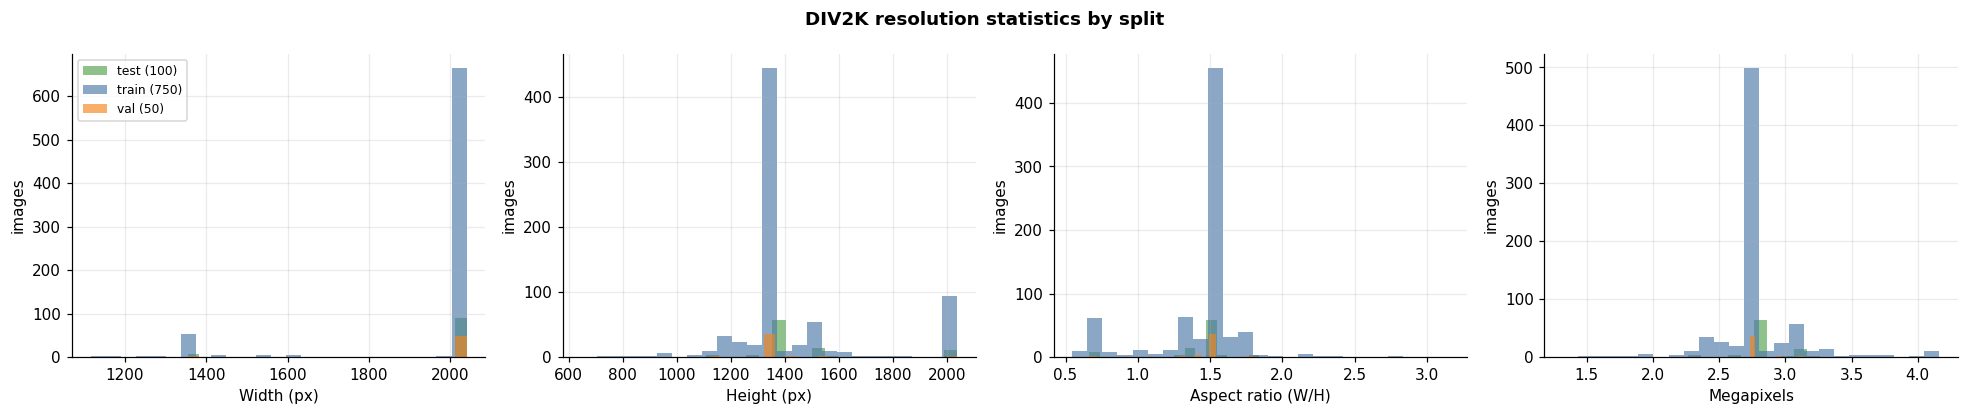

,images,mean_width,mean_height,mean_megapixels,portrait,nonoverlap_128_patches
split,,,,,,
test,100,1978.80,1450.92,2.84,10,15585
train,750,1968.75,1439.44,2.79,85,114360
val,50,2012.88,1371.12,2.74,2,7485


Stored patch bank: 12,000 patches of 192px. Each yields 4,225 distinct 128px crops x 8 flip/rotation variants, plus a fresh random degradation every time it is sampled.


In [10]:
# ── 2.5  EDA: resolution and patch statistics ──────────────────────────────────
split_of = {n: s for s, names in SPLITS.items() for n in names}
use = audit[audit["usable"]].copy()
use["split"] = use["name"].map(split_of).fillna("unused")
use["megapixels"] = use["width"] * use["height"] / 1e6
use["aspect"] = use["width"] / use["height"]
use["patches_128"] = (use["width"] // CFG.crop) * (use["height"] // CFG.crop)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
split_colors = {"train": "#4c78a8", "val": "#f58518", "test": "#54a24b", "unused": "#bbbbbb"}
for ax, col, label in zip(axes, ["width", "height", "aspect", "megapixels"],
                          ["Width (px)", "Height (px)", "Aspect ratio (W/H)", "Megapixels"]):
    for s, grp in use.groupby("split"):
        ax.hist(grp[col], bins=25, alpha=0.65, label=f"{s} ({len(grp)})", color=split_colors.get(s))
    ax.set_xlabel(label)
    ax.set_ylabel("images")
axes[0].legend(fontsize=8)
fig.suptitle("DIV2K resolution statistics by split", fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_resolution")
plt.show()

summary = use.groupby("split").agg(
    images=("name", "count"), mean_width=("width", "mean"), mean_height=("height", "mean"),
    mean_megapixels=("megapixels", "mean"), portrait=("aspect", lambda a: int((a < 1).sum())),
    nonoverlap_128_patches=("patches_128", "sum")).round(2)
display(summary)

positions = (CFG.patch_store - CFG.crop + 1) ** 2
print(f"Stored patch bank: {PATCH_SHAPE[0]:,} patches of {CFG.patch_store}px. Each yields {positions:,} distinct "
      f"{CFG.crop}px crops x 8 flip/rotation variants, plus a fresh random degradation every time it is sampled.")

EDA statistics: 100%|██████████| 80/80 [00:09<00:00,  8.40it/s]


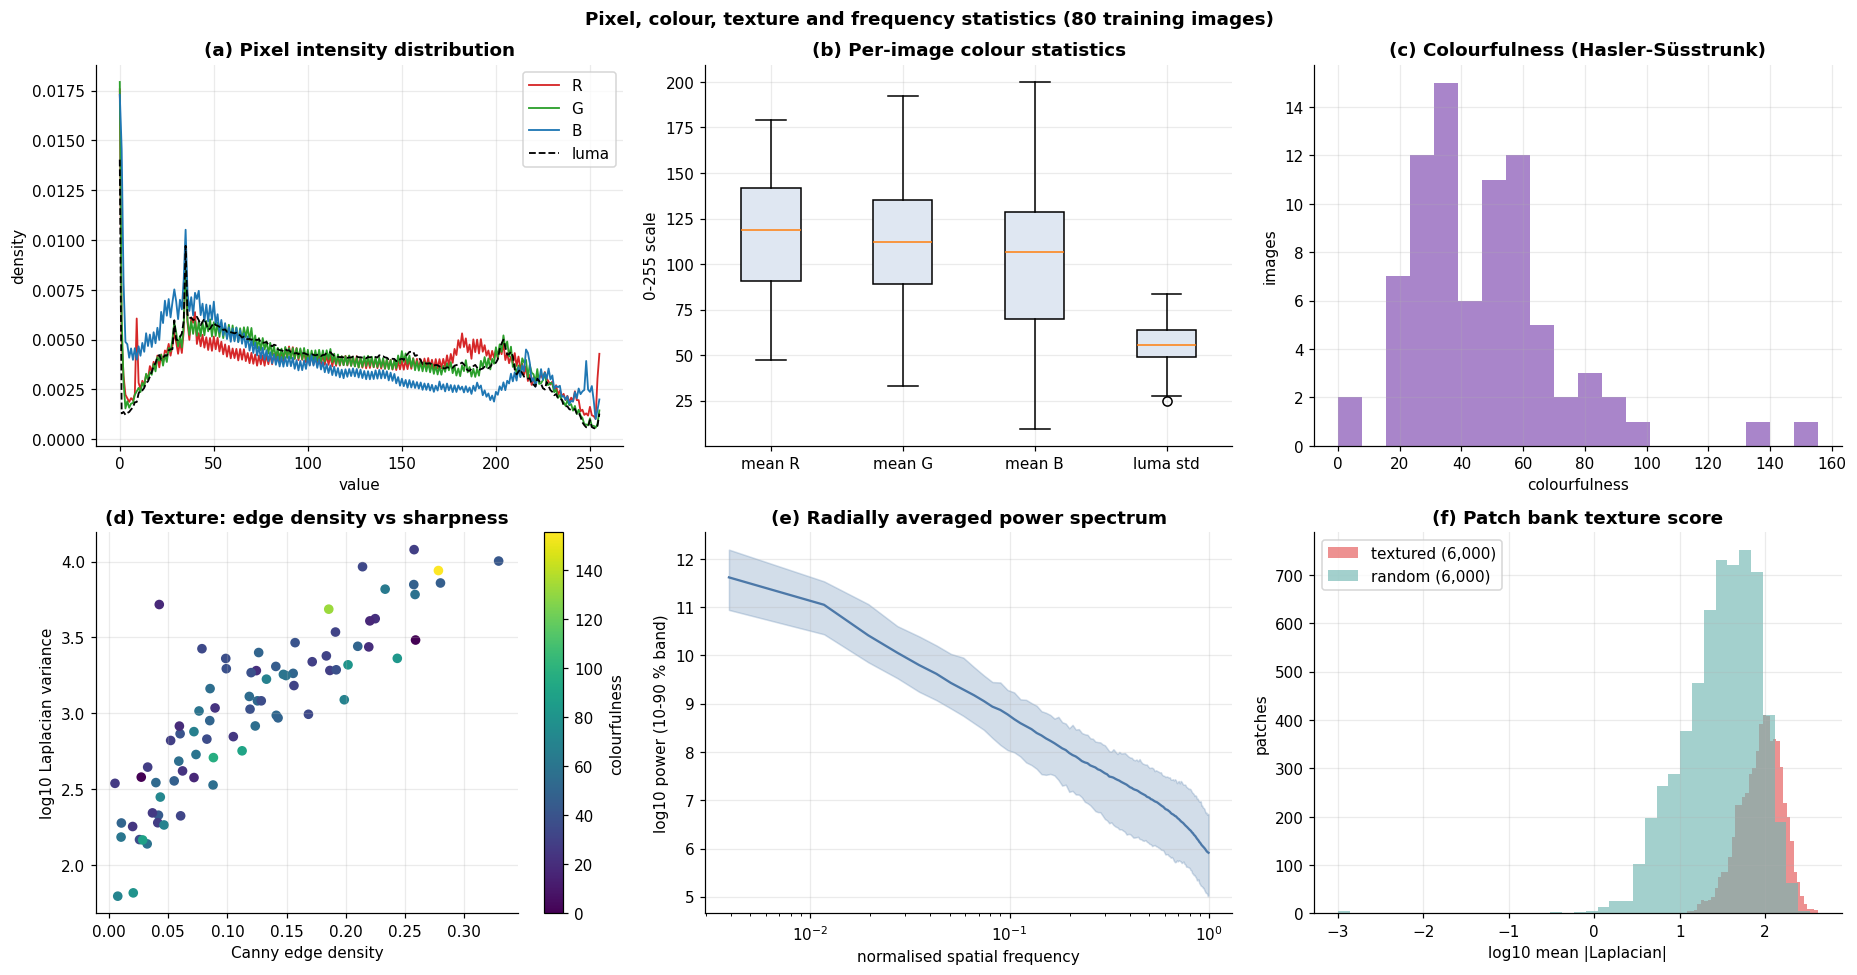

,mean,std,min,50%,max
mean_r,117.114,34.432,47.355,118.856,179.192
mean_g,113.007,33.408,33.135,112.318,192.073
mean_b,102.866,40.976,9.721,106.855,199.931
lum_std,56.890,12.453,24.766,55.623,83.793
colorfulness,47.271,25.337,0.000,44.583,155.496
edge_density,0.121,0.079,0.005,0.115,0.329
laplacian_var,2034.203,2475.918,61.366,1145.286,11973.853


In [11]:
# ── 2.6  EDA: pixel, colour, texture and frequency statistics ───────────────────
def radial_power_spectrum(gray: np.ndarray, nbins: int = 128) -> np.ndarray:
    g = gray.astype(np.float32)
    g -= g.mean()
    g *= np.outer(np.hanning(g.shape[0]), np.hanning(g.shape[1])).astype(np.float32)
    P = np.abs(np.fft.fftshift(np.fft.fft2(g))) ** 2
    h, w = P.shape
    yy, xx = np.indices(P.shape)
    r = np.hypot(yy - h / 2, xx - w / 2) / (min(h, w) / 2)
    m = r < 1
    bins = (r[m] * nbins).astype(int)
    return np.bincount(bins, P[m], nbins) / np.maximum(np.bincount(bins, minlength=nbins), 1)


_rng = np.random.default_rng(CFG.seed + 2)
eda_names = sorted(_rng.choice(SPLITS["train"], size=min(80, len(SPLITS["train"])), replace=False).tolist())
ch_hist, lum_hist, spectra, rows = np.zeros((3, 256)), np.zeros(256), [], []
for name in tqdm(eda_names, desc="EDA statistics"):
    img = load_rgb(name)
    small = cv2.resize(img, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    gray_s = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
    lum_hist += np.bincount(gray_s.ravel(), minlength=256)
    for c in range(3):
        ch_hist[c] += np.bincount(small[..., c].ravel(), minlength=256)
    sf = small.astype(np.float32)
    rg, yb = sf[..., 0] - sf[..., 1], 0.5 * (sf[..., 0] + sf[..., 1]) - sf[..., 2]
    crop_gray = cv2.cvtColor(center_crop(img, 512), cv2.COLOR_RGB2GRAY)     # native-resolution texture
    spectra.append(radial_power_spectrum(crop_gray))
    rows.append({
        "name": name, "mean_r": sf[..., 0].mean(), "mean_g": sf[..., 1].mean(), "mean_b": sf[..., 2].mean(),
        "lum_std": gray_s.std(),
        "colorfulness": math.hypot(rg.std(), yb.std()) + 0.3 * math.hypot(rg.mean(), yb.mean()),
        "edge_density": float((cv2.Canny(crop_gray, 100, 200) > 0).mean()),
        "laplacian_var": float(cv2.Laplacian(crop_gray, cv2.CV_64F).var()),
    })
eda = pd.DataFrame(rows)
eda.to_csv(DIRS["results"] / "eda_image_stats.csv", index=False)
patch_meta = pd.read_csv(PATCH_META, dtype={"name": str})

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
x = np.arange(256)
for c, col in enumerate(["#d62728", "#2ca02c", "#1f77b4"]):
    ax[0, 0].plot(x, ch_hist[c] / ch_hist[c].sum(), color=col, lw=1.2, label="RGB"[c])
ax[0, 0].plot(x, lum_hist / lum_hist.sum(), "k--", lw=1.2, label="luma")
ax[0, 0].set(title="(a) Pixel intensity distribution", xlabel="value", ylabel="density")
ax[0, 0].legend()

ax[0, 1].boxplot([eda["mean_r"], eda["mean_g"], eda["mean_b"], eda["lum_std"]], patch_artist=True,
                 boxprops=dict(facecolor="#dfe7f2"))
ax[0, 1].set_xticks([1, 2, 3, 4], ["mean R", "mean G", "mean B", "luma std"])
ax[0, 1].set(title="(b) Per-image colour statistics", ylabel="0-255 scale")

ax[0, 2].hist(eda["colorfulness"], bins=20, color="#9467bd", alpha=0.8)
ax[0, 2].set(title="(c) Colourfulness (Hasler-Süsstrunk)", xlabel="colourfulness", ylabel="images")

sc = ax[1, 0].scatter(eda["edge_density"], np.log10(eda["laplacian_var"] + 1), c=eda["colorfulness"],
                      cmap="viridis", s=28)
fig.colorbar(sc, ax=ax[1, 0], label="colourfulness")
ax[1, 0].set(title="(d) Texture: edge density vs sharpness", xlabel="Canny edge density",
             ylabel="log10 Laplacian variance")

S = np.log10(np.stack(spectra) + 1e-8)
f = (np.arange(S.shape[1]) + 0.5) / S.shape[1]
ax[1, 1].plot(f, S.mean(0), color="#4c78a8")
ax[1, 1].fill_between(f, np.percentile(S, 10, 0), np.percentile(S, 90, 0), alpha=0.25, color="#4c78a8")
ax[1, 1].set_xscale("log")
ax[1, 1].set(title="(e) Radially averaged power spectrum", xlabel="normalised spatial frequency",
             ylabel="log10 power (10-90 % band)")

for kind, col in [("textured", "#e45756"), ("random", "#72b7b2")]:
    v = patch_meta.loc[patch_meta["kind"] == kind, "texture"]
    ax[1, 2].hist(np.log10(v + 1e-3), bins=40, alpha=0.65, color=col, label=f"{kind} ({len(v):,})")
ax[1, 2].set(title="(f) Patch bank texture score", xlabel="log10 mean |Laplacian|", ylabel="patches")
ax[1, 2].legend()
fig.suptitle(f"Pixel, colour, texture and frequency statistics ({len(eda_names)} training images)",
             fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_pixel_texture")
plt.show()
display(eda.drop(columns="name").describe().T[["mean", "std", "min", "50%", "max"]].round(3))

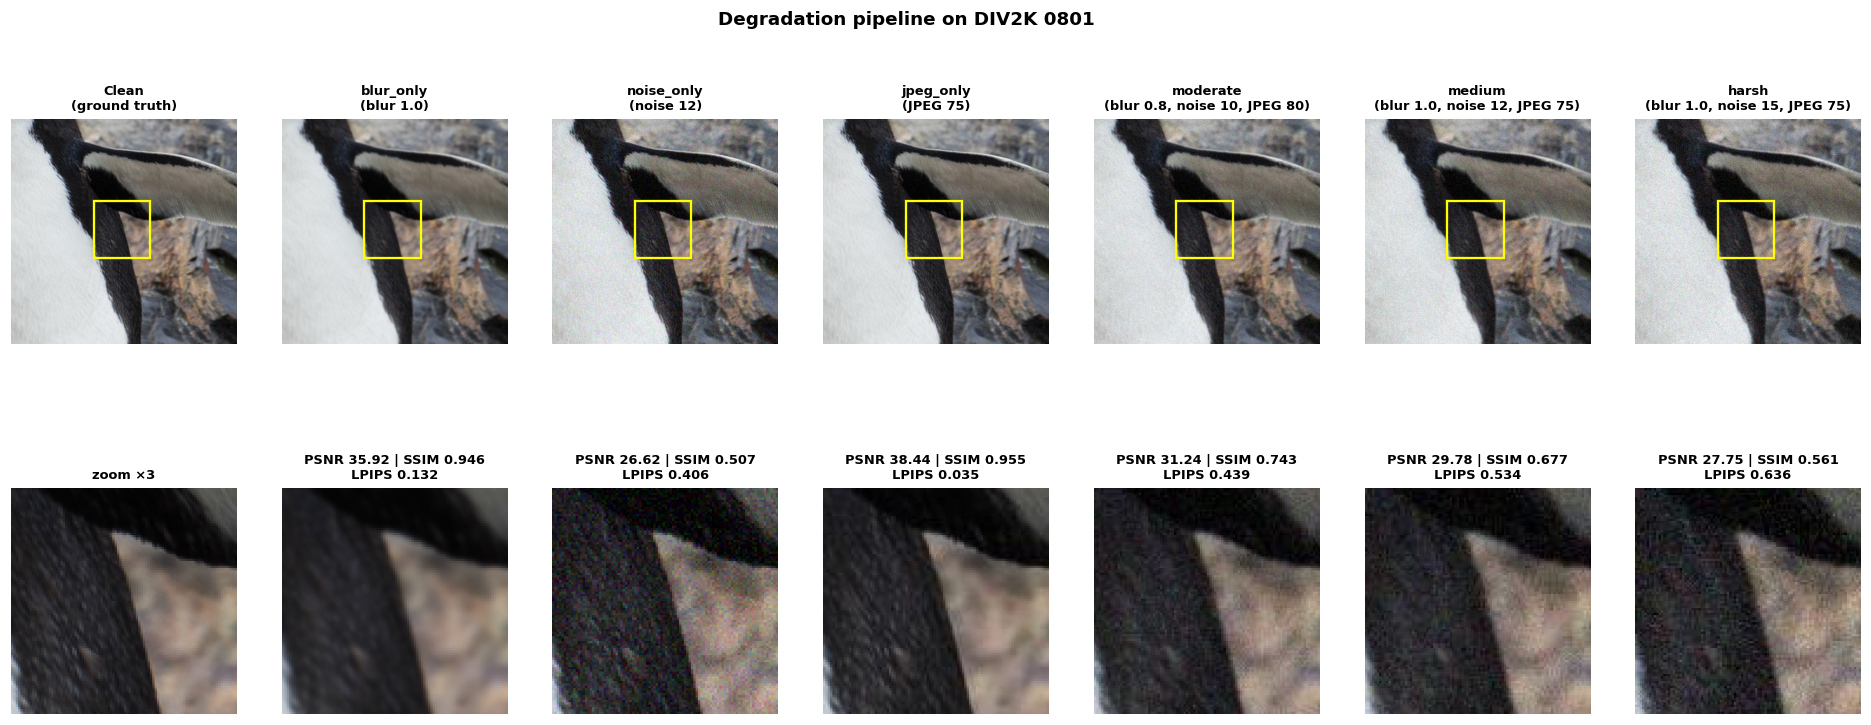

,psnr,ssim,lpips,psnr_y,ssim_y
preset,,,,,
blur_only,28.836,0.868,0.240,30.230,0.879
noise_only,26.769,0.632,0.191,31.526,0.793
jpeg_only,33.973,0.934,0.031,37.558,0.961
moderate,27.684,0.739,0.302,29.499,0.785
medium,26.225,0.666,0.404,27.951,0.717
harsh,25.152,0.584,0.488,26.812,0.636


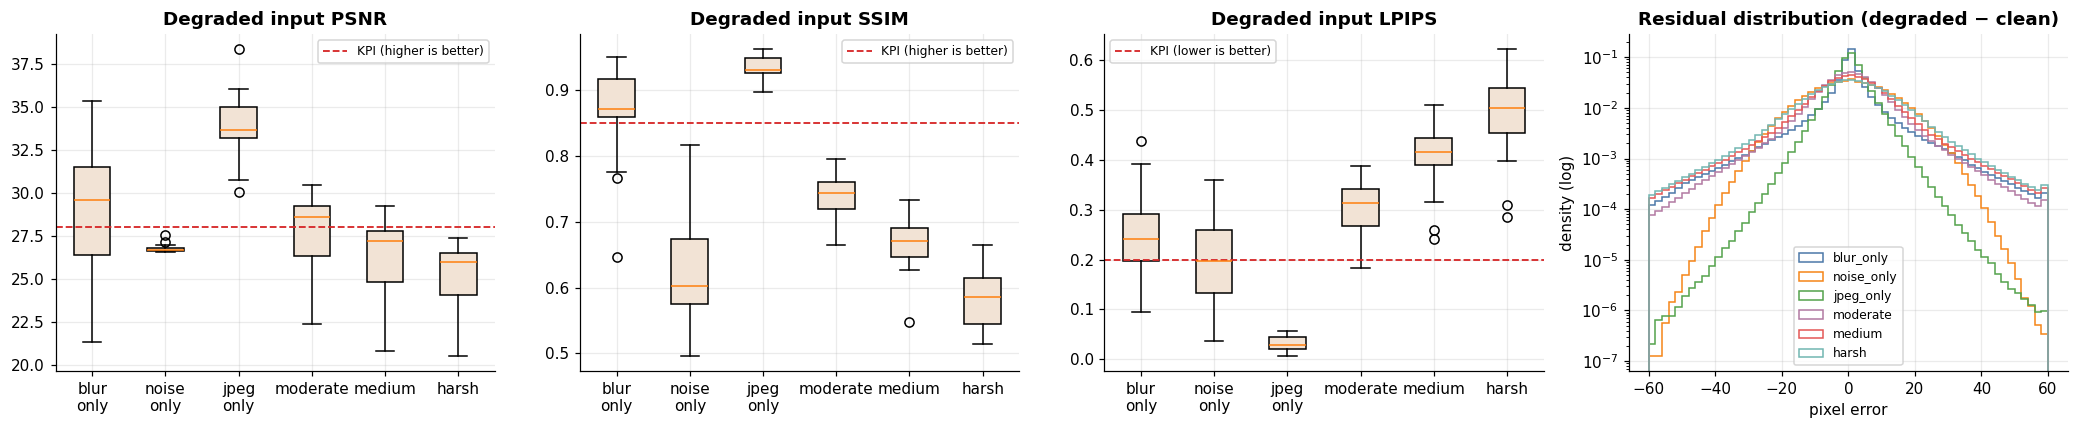

In [12]:
# ── 2.7  EDA: degradation visualisation and degraded-input quality ──────────────
demo_name = SPLITS["test"][0]
demo_hr = center_crop(load_rgb(demo_name), 384)
order = list(CFG.eval_presets)
variants = [("Clean (ground truth)", demo_hr)] + [(preset_label(p), degrade_preset(demo_hr, p, demo_name)) for p in order]

zy, zx, zs = 140, 140, 96          # zoom window
fig, axes = plt.subplots(2, len(variants), figsize=(3.1 * len(variants), 7.6),
                         gridspec_kw={"hspace": 0.35})
for j, (title, im) in enumerate(variants):
    m = compute_metrics(im, demo_hr) if j else None
    axes[0, j].imshow(im)
    axes[0, j].add_patch(plt.Rectangle((zx, zy), zs, zs, fill=False, ec="yellow", lw=1.5))
    axes[0, j].set_title(title.replace(" (", "\n("), fontsize=8.5)
    axes[1, j].imshow(cv2.resize(im[zy:zy + zs, zx:zx + zs], None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST))
    axes[1, j].set_title("zoom ×3" if m is None else
                         f"PSNR {m['psnr']:.2f} | SSIM {m['ssim']:.3f}\nLPIPS {m['lpips']:.3f}", fontsize=8.5)
    for a in axes[:, j]:
        a.axis("off")
fig.suptitle(f"Degradation pipeline on DIV2K {demo_name}", fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_degradations")
plt.show()

# quality of the *degraded inputs* = the starting point every model must improve on
rows = []
for p in order:
    for i, n in enumerate(ABL["names"]):
        rows.append({"preset": p, "image": n, **compute_metrics(ABL["lq"][p][i], ABL["hr"][i])})
input_q = pd.DataFrame(rows)
input_q.to_csv(DIRS["results"] / "input_quality_by_preset.csv", index=False)
iq = input_q.groupby("preset")[["psnr", "ssim", "lpips", "psnr_y", "ssim_y"]].mean().reindex(order).round(4)
display(iq.style.set_caption("Degraded-input quality (no restoration) - ablation subset").format(precision=3))

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, metric, kpi, better in [(axes[0], "psnr", CFG.kpi["psnr"], "higher"),
                                (axes[1], "ssim", CFG.kpi["ssim"], "higher"),
                                (axes[2], "lpips", CFG.kpi["lpips"], "lower")]:
    data = [input_q.loc[input_q["preset"] == p, metric] for p in order]
    ax.boxplot(data, patch_artist=True, boxprops=dict(facecolor="#f2e3d5"))
    ax.set_xticks(range(1, len(order) + 1), [p.replace("_", "\n") for p in order])
    ax.axhline(kpi, color="#d62728", ls="--", lw=1.2, label=f"KPI ({better} is better)")
    ax.set_title(f"Degraded input {metric.upper()}")
    ax.legend(fontsize=8)
bins = np.arange(-60, 61, 2)
for p, col in zip(order, ["#4c78a8", "#f58518", "#54a24b", "#b279a2", "#e45756", "#72b7b2"]):
    resid = ABL["lq"][p].astype(np.int16) - ABL["hr"].astype(np.int16)
    axes[3].hist(resid.ravel(), bins=bins, density=True, histtype="step", lw=1.4, color=col, label=p)
axes[3].set_yscale("log")
axes[3].set(title="Residual distribution (degraded − clean)", xlabel="pixel error", ylabel="density (log)")
axes[3].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "eda_input_quality")
plt.show()

Train batches: 375 per epoch | batch LQ (32, 3, 128, 128) HR (32, 3, 128, 128) | range [0.00, 1.00] | workers 0
Validation pairs: (50, 3, 256, 256) (medium preset)
Loader throughput: 964 samples/s


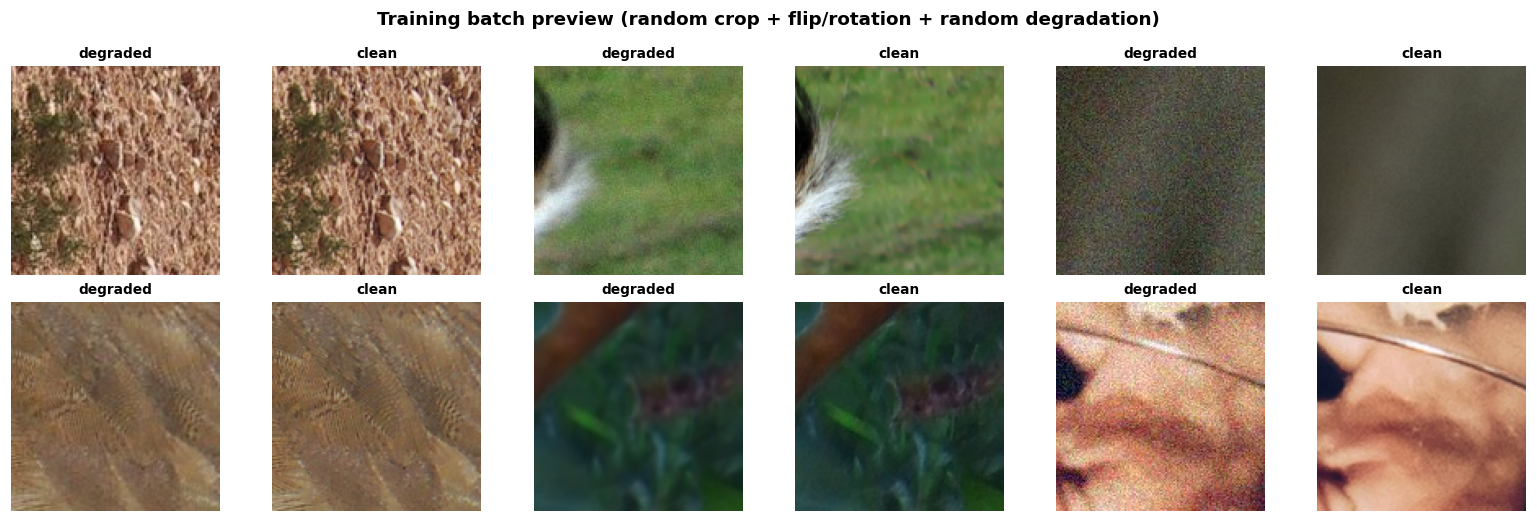

In [13]:
# ── 2.8  Training dataset, data loader and validation pairs ─────────────────────
class DIV2KPatchDataset(Dataset):
    """Random 128px crops from the cached patch bank with flips/rotations and on-the-fly random degradation."""

    def __init__(self, patch_file: Path, crop: int):
        self.patch_file = str(patch_file)
        self.n = int(np.load(self.patch_file, mmap_mode="r").shape[0])
        self.arr = None                                         # opened lazily inside each worker
        self.aug = A.Compose([
            A.RandomCrop(height=crop, width=crop),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
        ])

    def __len__(self) -> int:
        return self.n

    def __getitem__(self, i: int):
        if self.arr is None:
            self.arr = np.load(self.patch_file, mmap_mode="r")
        hr = np.ascontiguousarray(self.aug(image=np.asarray(self.arr[i]))["image"])
        rng = np.random.default_rng(int(torch.randint(0, 2**31 - 1, (1,)).item()))
        lq = degrade(hr, **sample_degradation(rng), rng=rng)
        to_t = lambda im: torch.from_numpy(np.ascontiguousarray(im)).permute(2, 0, 1).float().div_(255.0)
        return to_t(lq), to_t(hr)


def _worker_init(worker_id: int) -> None:
    seed = (torch.initial_seed() + worker_id) % 2**32
    random.seed(seed)
    np.random.seed(seed)
    cv2.setNumThreads(0)
    info = get_worker_info()
    if info is not None and hasattr(info.dataset.aug, "set_random_seed"):
        info.dataset.aug.set_random_seed(seed)                  # albumentations >= 2 keeps its own RNG


def make_train_loader(batch_size: int | None = None) -> DataLoader:
    ds = DIV2KPatchDataset(PATCH_LOCAL, CFG.crop)
    return DataLoader(ds, batch_size=batch_size or CFG.batch_size, shuffle=True, drop_last=True,
                      num_workers=CFG.num_workers, pin_memory=torch.cuda.is_available(),
                      persistent_workers=CFG.num_workers > 0, worker_init_fn=_worker_init)


def infinite(loader: DataLoader):
    while True:
        for batch in loader:
            yield batch


def build_val_pairs():
    """Fixed validation crops (KPI preset) used to monitor PSNR during training."""
    hr = [center_crop(load_rgb(n), CFG.val_crop) for n in SPLITS["val"]]
    lq = [degrade_preset(h, CFG.kpi_preset, n) for h, n in zip(hr, SPLITS["val"])]
    stack = lambda ims: torch.from_numpy(np.stack(ims)).permute(0, 3, 1, 2).float().div_(255.0)
    return stack(lq), stack(hr)


train_loader = make_train_loader()
VAL_LQ, VAL_HR = build_val_pairs()
lq_b, hr_b = next(iter(train_loader))
print(f"Train batches: {len(train_loader)} per epoch | batch LQ {tuple(lq_b.shape)} HR {tuple(hr_b.shape)} "
      f"| range [{lq_b.min():.2f}, {lq_b.max():.2f}] | workers {CFG.num_workers}")
print(f"Validation pairs: {tuple(VAL_LQ.shape)} ({CFG.kpi_preset} preset)")

_t = time.time()
for _i, _ in zip(range(10), train_loader):
    pass
print(f"Loader throughput: {10 * CFG.batch_size / (time.time() - _t):.0f} samples/s")

pairs = []
for i in range(6):
    pairs += [(lq_b[i].permute(1, 2, 0).numpy() * 255).astype(np.uint8),
              (hr_b[i].permute(1, 2, 0).numpy() * 255).astype(np.uint8)]
show_images(pairs, ["degraded", "clean"] * 6, ncols=6, size=2.4,
            suptitle="Training batch preview (random crop + flip/rotation + random degradation)",
            name="train_batch_preview")

## 2.9 EDA findings and how they shape the design

- **High resolution, consistent aspect ratio.** Almost every DIV2K image is about 2040 px on its long side (~2.8 MP), in landscape or portrait orientation (plot 2.5). One image provides hundreds of non-overlapping 128 px patches, so **patch-based training** on a compact patch bank loses little diversity while cutting cost per step by about 4× compared with 256 px crops. Full-resolution evaluation needs **overlapping tiled inference** to fit in T4 memory.
- **Wide intensity and colour range** (plots 2.6 a–c). Pixel values cover the full 0–255 range with large differences in colourfulness between images, so the model works directly in RGB without per-dataset normalisation, and JPEG is applied in the correct BGR→YCbCr order so chroma subsampling artifacts are realistic.
- **Strong variation in texture** (plots 2.6 d, f). Edge density and Laplacian variance differ by orders of magnitude across images and within each image; large flat regions (sky, walls) are common. The patch bank therefore mixes **texture-weighted and random patches**, so the model learns to restore fine detail without hallucinating texture in flat areas.
- **Natural-image power spectrum** (plot 2.6 e). Power falls off steadily with frequency. Blur removes exactly the weak high-frequency band that carries fine detail, and noise adds power across all frequencies. Separating the two is the core difficulty, and it is why a regression model alone tends to over-smooth.
- **Degraded-input quality** (plot 2.7). Single degradations are mild: JPEG-only and blur-only inputs already score well on PSNR, and even `moderate` sits close to 28 dB before any restoration. The KPI preset `medium` puts the damaged input below **all three** targets on average (about 27 dB, LPIPS about 0.4), so the KPIs measure real restoration rather than a near-identity mapping. `harsh` is a clearly harder stress test.
- **Error distributions.** Noise gives wide, symmetric residual tails; blur and JPEG give narrow, structured errors concentrated at edges and 8×8 block boundaries. This motivates a combined loss: L1 for pixel accuracy, plus a perceptual term and the diffusion prior for texture.

# 3. Shared Building Blocks

Everything the three models share lives here, so that §4–§5 only define what is specific to each model:

| Cell | Contents |
|---|---|
| 3.1 | GPU timer, Charbonnier loss, quick validation PSNR, result summaries with KPI flags |
| 3.2 | Overlapping **tiled inference** for full-resolution images, with smooth blending and an automatic **out-of-memory fallback** |
| 3.3 | Network parts (ResBlock, Swin window attention, global attention) and the two architectures: **R0Net** (pretrained ResNet-18 U-Net) and **DiffusionUNet** (used by B0, F1 and the ablations) |
| 3.4 | Diffusion maths: cosine noise schedule, forward noising, fast **DDIM sampler** |
| 3.5 | Time-boxed **training loop** (AMP, EMA, checkpoint/resume) and the **evaluation routine** |

In [14]:
# ── 3.1  Timing, losses, validation and summaries ───────────────────────────────
import copy

USE_AMP = CFG.amp and DEVICE.type == "cuda"


def autocast():
    """fp16 autocast on GPU (T4 has no bf16), no-op on CPU."""
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP)


class GpuTimer:
    """Wall-clock timer that synchronises the GPU before and after the timed block."""

    def __enter__(self):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        self.t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        self.s = time.perf_counter() - self.t0


def charbonnier(pred: torch.Tensor, target: torch.Tensor, eps: float = 1e-3) -> torch.Tensor:
    return torch.sqrt((pred - target) ** 2 + eps ** 2).mean()


def count_params(model: nn.Module, trainable_only: bool = False) -> float:
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only) / 1e6


VAL_N = min(16, len(VAL_LQ))          # quick validation subset used during training


@torch.no_grad()
def val_psnr(restore_batch_fn) -> float:
    """Mean RGB PSNR of restore_batch_fn(lq01) on the fixed validation crops."""
    lq, hr = VAL_LQ[:VAL_N].to(DEVICE), VAL_HR[:VAL_N].to(DEVICE)
    with autocast():
        out = restore_batch_fn(lq)
    out = (out.float().clamp(0, 1) * 255).round()
    mse = ((out - hr * 255) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10)
    return float((10 * torch.log10(255.0 ** 2 / mse)).mean())


METRIC_COLS = ["psnr", "ssim", "lpips", "psnr_y", "ssim_y", "latency_s"]


def summarize(frames) -> pd.DataFrame:
    """Mean metrics per model plus KPI pass/fail flags."""
    df = pd.concat(list(frames), ignore_index=True)
    s = df.groupby("model", sort=False)[METRIC_COLS].mean()
    s.insert(0, "images", df.groupby("model", sort=False).size())
    s["PSNR ≥ 28"] = s["psnr"] >= CFG.kpi["psnr"]
    s["SSIM ≥ 0.85"] = s["ssim"] >= CFG.kpi["ssim"]
    s["LPIPS ≤ 0.20"] = s["lpips"] <= CFG.kpi["lpips"]
    return s


def style_summary(s: pd.DataFrame, caption: str):
    fmt = {"psnr": "{:.2f}", "ssim": "{:.4f}", "lpips": "{:.4f}", "psnr_y": "{:.2f}",
           "ssim_y": "{:.4f}", "latency_s": "{:.3f}"}
    flag = lambda v: "background-color:#d4edda;color:#155724" if v else "background-color:#f8d7da;color:#721c24"
    flags = [c for c in s.columns if c.startswith(("PSNR ≥", "SSIM ≥", "LPIPS ≤"))]
    sty = s.style.format(fmt).set_caption(caption)
    return sty.map(flag, subset=flags) if hasattr(sty, "map") else sty.applymap(flag, subset=flags)


print(f"AMP: {USE_AMP} | validation subset: {VAL_N} crops of {CFG.val_crop}px")

AMP: True | validation subset: 16 crops of 256px


In [15]:
# ── 3.2  Tiled inference with blending + out-of-memory fallback ─────────────────
def _ceil_to(v: int, m: int) -> int:
    return int(math.ceil(v / m) * m)


def _ramp(n: int, overlap: int, device) -> torch.Tensor:
    r = torch.ones(n, device=device)
    if overlap > 0 and n > 2 * overlap:
        k = torch.arange(1, overlap + 1, device=device, dtype=torch.float32) / (overlap + 1)
        r[:overlap], r[-overlap:] = k, k.flip(0)
    return r


def _positions(size: int, tile: int, stride: int) -> list:
    pos = list(range(0, max(size - tile, 0) + 1, stride))
    if pos[-1] + tile < size:
        pos.append(size - tile)
    return pos


@torch.no_grad()
def tiled_apply(fn, inputs: list, tile: int, overlap: int, batch: int, multiple: int = 32) -> torch.Tensor:
    """Apply fn(*tiles) -> (B, 3, t, t) over overlapping tiles of same-sized inputs (1, C, H, W).
    Tiles are blended with linear ramps so seams vanish; output is (1, 3, H, W) float32."""
    _, _, H, W = inputs[0].shape
    Hp, Wp = _ceil_to(H, multiple), _ceil_to(W, multiple)
    padded = [F.pad(x, (0, Wp - W, 0, Hp - H), mode="replicate") if (Hp, Wp) != (H, W) else x for x in inputs]
    th, tw = min(tile, Hp), min(tile, Wp)
    ov = min(overlap, th // 4, tw // 4)
    ys, xs = _positions(Hp, th, th - ov), _positions(Wp, tw, tw - ov)
    coords = [(y, x) for y in ys for x in xs]
    weight = (_ramp(th, ov, inputs[0].device)[:, None] * _ramp(tw, ov, inputs[0].device)[None, :])[None, None]
    out = torch.zeros(1, 3, Hp, Wp, device=inputs[0].device)
    wsum = torch.zeros(1, 1, Hp, Wp, device=inputs[0].device)
    for i in range(0, len(coords), batch):
        chunk = coords[i:i + batch]
        # keep the batch shape constant (repeat the last tile) so cuDNN never re-tunes mid-image
        fill = chunk + [chunk[-1]] * (batch - len(chunk)) if len(coords) > batch else chunk
        tiles = [torch.cat([p[:, :, y:y + th, x:x + tw] for (y, x) in fill]) for p in padded]
        pred = fn(*tiles).float()
        for j, (y, x) in enumerate(chunk):
            out[:, :, y:y + th, x:x + tw] += pred[j:j + 1] * weight
            wsum[:, :, y:y + th, x:x + tw] += weight
    return (out / wsum)[:, :, :H, :W]


def safe_tiled_apply(fn, inputs: list, tile: int | None = None, batch: int | None = None) -> torch.Tensor:
    """tiled_apply that halves batch size, then tile size, whenever the GPU runs out of memory."""
    tile, batch = tile or CFG.tile, batch or CFG.tile_batch
    while True:
        try:
            return tiled_apply(fn, inputs, tile, CFG.tile_overlap, batch)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if batch > 1:
                batch //= 2
            elif tile > 64:
                tile //= 2
            else:
                raise
            print(f"[OOM] retrying with tile={tile}, batch={batch}")


def _name_seed(name: str) -> int:
    return (CFG.seed * 1_000_003 + zlib.crc32(str(name).encode())) % 2**31


def make_restorer(tensor_fn, needs_noise: bool = False):
    """Wrap a tensor function (tiles in [0,1]) into restore(lq_uint8, name) -> uint8 RGB.
    Diffusion models receive one full-image noise field (seeded per image) so overlapping tiles agree."""
    @torch.no_grad()
    def restore(lq: np.ndarray, name: str = "image") -> np.ndarray:
        x = torch.from_numpy(np.ascontiguousarray(lq)).to(DEVICE).permute(2, 0, 1)[None].float() / 255.0
        inputs = [x]
        if needs_noise:
            g = torch.Generator(device=DEVICE).manual_seed(_name_seed(name))
            inputs.append(torch.randn(x.shape, generator=g, device=DEVICE))
        with autocast():
            y = safe_tiled_apply(tensor_fn, inputs)
        return (y.clamp(0, 1)[0].permute(1, 2, 0) * 255).round().byte().cpu().numpy()
    return restore


# self-test: an identity function must reproduce the image exactly through tiling and blending
_img = (np.random.default_rng(0).random((300, 420, 3)) * 255).astype(np.uint8)
_rec = make_restorer(lambda t: t)(_img)
assert np.abs(_rec.astype(int) - _img).max() <= 1, "tiling self-test failed"
print("Tiled inference self-test passed (identity reproduced through overlapping tiles).")

Tiled inference self-test passed (identity reproduced through overlapping tiles).


In [16]:
# ── 3.3  Network blocks and architectures ───────────────────────────────────────
def GN(c: int) -> nn.GroupNorm:
    return nn.GroupNorm(8 if c % 8 == 0 else 1, c)


def zero_init(m: nn.Module) -> nn.Module:
    for p in m.parameters():
        nn.init.zeros_(p)
    return m


def timestep_embedding(t: torch.Tensor, dim: int) -> torch.Tensor:
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.cos(args), torch.sin(args)], dim=1)


class ResBlock(nn.Module):
    """GroupNorm-SiLU-Conv x2 with a skip connection and optional FiLM time conditioning."""

    def __init__(self, cin: int, cout: int, emb_dim: int | None = None, dropout: float = 0.0):
        super().__init__()
        self.n1, self.c1 = GN(cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.n2, self.c2 = GN(cout), zero_init(nn.Conv2d(cout, cout, 3, padding=1))
        self.drop = nn.Dropout(dropout)
        self.emb = nn.Linear(emb_dim, 2 * cout) if emb_dim else None
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, emb=None):
        h = self.n2(self.c1(F.silu(self.n1(x))))
        if self.emb is not None and emb is not None:
            s, b = self.emb(F.silu(emb))[:, :, None, None].chunk(2, dim=1)
            h = h * (1 + s) + b
        return self.skip(x) + self.c2(self.drop(F.silu(h)))


class WindowAttention(nn.Module):
    """Multi-head self-attention inside ws x ws windows with a learned relative position bias (Swin)."""

    def __init__(self, dim: int, heads: int, ws: int):
        super().__init__()
        self.heads, self.ws = heads, ws
        self.qkv, self.proj = nn.Linear(dim, 3 * dim), nn.Linear(dim, dim)
        self.rel_bias = nn.Parameter(torch.zeros((2 * ws - 1) ** 2, heads))
        nn.init.trunc_normal_(self.rel_bias, std=0.02)
        coords = torch.stack(torch.meshgrid(torch.arange(ws), torch.arange(ws), indexing="ij")).flatten(1)
        rel = (coords[:, :, None] - coords[:, None, :]).permute(1, 2, 0) + (ws - 1)
        self.register_buffer("rel_idx", rel[..., 0] * (2 * ws - 1) + rel[..., 1], persistent=False)

    def forward(self, x, mask=None):                       # x: (B*nW, N, C)
        Bn, N, C = x.shape
        q, k, v = self.qkv(x).reshape(Bn, N, 3, self.heads, C // self.heads).permute(2, 0, 3, 1, 4)
        bias = self.rel_bias[self.rel_idx.reshape(-1)].reshape(N, N, -1).permute(2, 0, 1)   # (heads, N, N)
        if mask is None:
            attn_mask = bias[None].expand(Bn, -1, -1, -1)
        else:                                                                               # mask: (nW, N, N)
            attn_mask = (bias[None] + mask[:, None]).repeat(Bn // mask.shape[0], 1, 1, 1)
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask.to(q.dtype))
        return self.proj(out.transpose(1, 2).reshape(Bn, N, C))


class SwinBlock(nn.Module):
    """(Shifted-)window Transformer block on (B, C, H, W) maps; pads to a multiple of the window."""

    def __init__(self, dim: int, heads: int = 4, ws: int = 8, shift: int = 0, emb_dim: int | None = None,
                 mlp_ratio: float = 2.0):
        super().__init__()
        self.ws, self.shift = ws, shift
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, heads, ws)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, hidden), nn.GELU(), nn.Linear(hidden, dim))
        self.film = nn.Linear(emb_dim, 2 * dim) if emb_dim else None
        self._masks = {}

    def _mask(self, Hp: int, Wp: int, device) -> torch.Tensor:
        key = (Hp, Wp, str(device))
        if key not in self._masks:
            ws, s = self.ws, self.shift
            img = torch.zeros(1, Hp, Wp, 1, device=device)
            cnt = 0
            for hs in (slice(0, -ws), slice(-ws, -s), slice(-s, None)):
                for wsl in (slice(0, -ws), slice(-ws, -s), slice(-s, None)):
                    img[:, hs, wsl, :] = cnt
                    cnt += 1
            mw = img.view(1, Hp // ws, ws, Wp // ws, ws, 1).permute(0, 1, 3, 2, 4, 5).reshape(-1, ws * ws)
            m = mw[:, None, :] - mw[:, :, None]
            self._masks[key] = m.masked_fill(m != 0, -100.0).masked_fill(m == 0, 0.0)
        return self._masks[key]

    def forward(self, x, emb=None):
        B, C, H, W = x.shape
        ws = self.ws
        ph, pw = (-H) % ws, (-W) % ws
        h = x.permute(0, 2, 3, 1)
        if ph or pw:
            h = F.pad(h, (0, 0, 0, pw, 0, ph))
        Hp, Wp = H + ph, W + pw
        y = self.norm1(h)
        if self.film is not None and emb is not None:
            s, b = self.film(F.silu(emb))[:, None, None, :].chunk(2, dim=-1)
            y = y * (1 + s) + b
        mask = None
        if self.shift:
            y = torch.roll(y, (-self.shift, -self.shift), dims=(1, 2))
            mask = self._mask(Hp, Wp, x.device)
        win = y.reshape(B, Hp // ws, ws, Wp // ws, ws, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, ws * ws, C)
        a = self.attn(win, mask)
        a = a.reshape(B, Hp // ws, Wp // ws, ws, ws, C).permute(0, 1, 3, 2, 4, 5).reshape(B, Hp, Wp, C)
        if self.shift:
            a = torch.roll(a, (self.shift, self.shift), dims=(1, 2))
        h = h + a
        h = h + self.mlp(self.norm2(h))
        return h[:, :H, :W].permute(0, 3, 1, 2).contiguous()


class GlobalAttention(nn.Module):
    """Full self-attention over all positions (SR3-style, used at the lowest resolution)."""

    def __init__(self, c: int, heads: int = 4):
        super().__init__()
        self.heads = heads
        self.norm, self.qkv = GN(c), nn.Conv2d(c, 3 * c, 1)
        self.proj = zero_init(nn.Conv2d(c, c, 1))

    def forward(self, x, emb=None):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(B, 3, self.heads, C // self.heads, H * W).permute(1, 0, 2, 4, 3)
        out = F.scaled_dot_product_attention(q, k, v)
        return x + self.proj(out.permute(0, 1, 3, 2).reshape(B, C, H, W))


class Stage(nn.Module):
    """One U-Net level: a ResBlock, optionally followed by a regular + shifted Swin block pair."""

    def __init__(self, cin: int, cout: int, emb_dim: int, swin: bool, heads: int, ws: int):
        super().__init__()
        self.res = ResBlock(cin, cout, emb_dim)
        self.swin = nn.ModuleList([SwinBlock(cout, heads, ws, 0, emb_dim), SwinBlock(cout, heads, ws, ws // 2, emb_dim)]
                                  ) if swin else nn.ModuleList()

    def forward(self, x, emb):
        x = self.res(x, emb)
        for blk in self.swin:
            x = blk(x, emb)
        return x


class DiffusionUNet(nn.Module):
    """Time-conditioned U-Net. swin_levels picks levels with Swin blocks; mid_attn is 'global', 'swin' or 'none';
    cond_chs maps a level index to the channels of an external feature map added at that level."""

    def __init__(self, in_ch: int, out_ch: int = 3, width: int = 48, mults=(1, 2, 4, 4), swin_levels=(),
                 mid_attn: str = "global", cond_chs: dict | None = None, heads: int = 4, ws: int = 8):
        super().__init__()
        self.width = width
        chs = [width * m for m in mults]
        emb = width * 4
        self.time_mlp = nn.Sequential(nn.Linear(width, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.inc = nn.Conv2d(in_ch, chs[0], 3, padding=1)
        self.down, self.downsample = nn.ModuleList(), nn.ModuleList()
        prev = chs[0]
        for i, c in enumerate(chs):
            self.down.append(Stage(prev, c, emb, i in swin_levels, heads, ws))
            self.downsample.append(nn.Conv2d(c, c, 3, stride=2, padding=1) if i < len(chs) - 1 else nn.Identity())
            prev = c
        self.mid1, self.mid2 = ResBlock(prev, prev, emb), ResBlock(prev, prev, emb)
        if mid_attn == "global":
            self.mid_attn = nn.ModuleList([GlobalAttention(prev, heads)])
        elif mid_attn == "swin":
            self.mid_attn = nn.ModuleList([SwinBlock(prev, heads, ws, 0, emb), SwinBlock(prev, heads, ws, ws // 2, emb)])
        else:
            self.mid_attn = nn.ModuleList()
        self.up = nn.ModuleList()
        for i in reversed(range(len(chs))):
            self.up.append(Stage(prev + chs[i], chs[i], emb, i in swin_levels, heads, ws))
            prev = chs[i]
        self.out = nn.Sequential(GN(chs[0]), nn.SiLU(), zero_init(nn.Conv2d(chs[0], out_ch, 3, padding=1)))
        self.cond_proj = nn.ModuleDict({str(l): zero_init(nn.Conv2d(c, chs[l], 1)) for l, c in (cond_chs or {}).items()})

    def forward(self, x, t, cond: dict | None = None):
        emb = self.time_mlp(timestep_embedding(t, self.width))
        h, skips = self.inc(x), []
        for i, (stage, ds) in enumerate(zip(self.down, self.downsample)):
            h = stage(h, emb)
            if cond is not None and str(i) in self.cond_proj:
                c = cond[i]
                if c.shape[-2:] != h.shape[-2:]:
                    c = F.interpolate(c, size=h.shape[-2:], mode="bilinear", align_corners=False)
                h = h + self.cond_proj[str(i)](c.to(h.dtype))
            skips.append(h)
            h = ds(h)
        h = self.mid1(h, emb)
        for blk in self.mid_attn:
            h = blk(h, emb)
        h = self.mid2(h, emb)
        for stage in self.up:
            skip = skips.pop()
            if h.shape[-2:] != skip.shape[-2:]:
                h = F.interpolate(h, size=skip.shape[-2:], mode="nearest")
            h = stage(torch.cat([h, skip], dim=1), emb)
        return self.out(h)


class R0Net(nn.Module):
    """Regression restorer: ImageNet-pretrained ResNet-18 encoder (timm) + U-Net decoder + global residual."""

    def __init__(self, width: int = 48, encoder: str = "resnet18", pretrained: bool = True):
        super().__init__()
        try:
            self.encoder = timm.create_model(encoder, pretrained=pretrained, features_only=True)
            self.pretrained = pretrained
        except Exception as e:
            print(f"Could not load pretrained weights ({e}); using random initialisation.")
            self.encoder = timm.create_model(encoder, pretrained=False, features_only=True)
            self.pretrained = False
        enc = self.encoder.feature_info.channels()                     # resnet18: [64, 64, 128, 256, 512]
        cfg = self.encoder.pretrained_cfg
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1), persistent=False)
        self.shallow = nn.Sequential(nn.Conv2d(3, width, 3, padding=1), nn.SiLU(), nn.Conv2d(width, width, 3, padding=1))
        skips = [width] + enc[:-1]                                    # strides 1, 2, 4, 8, 16
        dec = [256, 128, 64, 64, width]
        self.dec, prev = nn.ModuleList(), enc[-1]
        for s_ch, d_ch in zip(reversed(skips), dec):
            self.dec.append(ResBlock(prev + s_ch, d_ch))
            prev = d_ch
        self.head = zero_init(nn.Conv2d(width, 3, 3, padding=1))

    def features(self, x01: torch.Tensor) -> list:
        return self.encoder((x01 - self.mean) / self.std)

    def forward(self, x01: torch.Tensor, return_feats: bool = False):
        feats = self.features(x01)
        skips = [self.shallow(x01)] + feats[:-1]
        h = feats[-1]
        for blk, skip in zip(self.dec, reversed(skips)):
            h = F.interpolate(h, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            h = blk(torch.cat([h, skip.to(h.dtype)], dim=1))
        out = x01 + self.head(h)
        return (out, feats) if return_feats else out


# shape check on a 128 crop for every architecture used in this notebook
with torch.no_grad():
    _x = torch.rand(2, 3, 128, 128, device=DEVICE)
    _t = torch.randint(0, CFG.T, (2,), device=DEVICE)
    _r0 = R0Net(CFG.width).to(DEVICE).eval()
    _o, _f = _r0(_x, return_feats=True)
    _b0 = DiffusionUNet(6, width=CFG.width).to(DEVICE)
    _f1 = DiffusionUNet(9, width=CFG.width, swin_levels=(2, 3), mid_attn="swin", cond_chs={2: 64, 3: 128}).to(DEVICE)
    assert _o.shape == _x.shape and _b0(torch.cat([_x, _x], 1), _t).shape == _x.shape
    assert _f1(torch.cat([_x, _x, _x], 1), _t, {2: _f[1], 3: _f[2]}).shape == _x.shape
print(pd.DataFrame({
    "architecture": ["R0Net (ResNet-18 U-Net)", "DiffusionUNet - B0 config", "DiffusionUNet - F1 config (CNN + Swin)"],
    "params (M)": [count_params(_r0), count_params(_b0), count_params(_f1)],
    "ImageNet-pretrained": [_r0.pretrained, False, "uses R0 encoder features"],
}).round(2).to_string(index=False))
del _r0, _b0, _f1, _o, _f

                          architecture  params (M)      ImageNet-pretrained
               R0Net (ResNet-18 U-Net)       14.75                     True
             DiffusionUNet - B0 config        6.47                    False
DiffusionUNet - F1 config (CNN + Swin)       10.08 uses R0 encoder features


In [17]:
# ── 3.4  Diffusion: cosine schedule, forward noising, DDIM sampler ──────────────
class Diffusion:
    """Gaussian diffusion with the cosine schedule (Nichol & Dhariwal 2021) and a deterministic DDIM sampler."""

    def __init__(self, T: int = 1000, s: float = 0.008):
        self.T = T
        steps = torch.arange(T + 1, dtype=torch.float64) / T
        f = torch.cos((steps + s) / (1 + s) * math.pi / 2) ** 2
        betas = (1 - f[1:] / f[:-1]).clamp(max=0.999)
        self.ab = torch.cumprod(1 - betas, dim=0).float()               # alpha-bar for t = 0..T-1

    def _ab(self, t: torch.Tensor, like: torch.Tensor) -> torch.Tensor:
        return self.ab.to(like.device)[t].view(-1, 1, 1, 1)

    def q_sample(self, x0: torch.Tensor, t: torch.Tensor, noise: torch.Tensor) -> torch.Tensor:
        ab = self._ab(t, x0)
        return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

    def sample_t(self, n: int) -> torch.Tensor:
        return torch.randint(0, self.T, (n,), device=DEVICE)

    @torch.no_grad()
    def ddim(self, model_fn, x_T: torch.Tensor, steps: int, pred: str = "eps", clip: float = 1.0) -> torch.Tensor:
        """Deterministic DDIM (eta = 0). model_fn(x_t, t) predicts 'eps', 'x0' or 'v'
        (v = sqrt(ab)·eps − sqrt(1−ab)·x0, Salimans & Ho 2022). Returns the final x0 estimate."""
        ab = self.ab.to(x_T.device)
        ts = torch.linspace(self.T - 1, 0, steps, device=x_T.device).round().long()
        x = x_T.float()
        x0 = x
        for i, t in enumerate(ts):
            a_t = ab[t]
            a_prev = ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=x.device)
            out = model_fn(x, t.repeat(x.shape[0])).float()
            if pred == "eps":
                x0 = ((x - (1 - a_t).sqrt() * out) / a_t.sqrt()).clamp(-clip, clip)
            elif pred == "v":
                x0 = (a_t.sqrt() * x - (1 - a_t).sqrt() * out).clamp(-clip, clip)
            else:
                x0 = out.clamp(-clip, clip)
            eps = (x - a_t.sqrt() * x0) / (1 - a_t).sqrt()
            x = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps
        return x0


DIFF = Diffusion(CFG.T)
_ab = DIFF.ab
print(f"Cosine schedule: T={CFG.T} | alpha_bar[0]={_ab[0]:.5f}  alpha_bar[T/2]={_ab[CFG.T // 2]:.3f}  "
      f"alpha_bar[T-1]={_ab[-1]:.2e}")
print(f"DDIM timesteps (F1, {CFG.f1_steps} steps):", torch.linspace(CFG.T - 1, 0, CFG.f1_steps).round().long().tolist())
print(f"DDIM timesteps (B0, {CFG.b0_steps} steps):", torch.linspace(CFG.T - 1, 0, CFG.b0_steps).round().long().tolist())

Cosine schedule: T=1000 | alpha_bar[0]=0.99996  alpha_bar[T/2]=0.492  alpha_bar[T-1]=2.43e-09
DDIM timesteps (F1, 4 steps): [999, 666, 333, 0]
DDIM timesteps (B0, 25 steps): [999, 957, 916, 874, 832, 791, 749, 708, 666, 624, 583, 541, 500, 458, 416, 375, 333, 291, 250, 208, 166, 125, 83, 42, 0]


In [18]:
# ── 3.5  Time-boxed training loop (AMP, EMA, checkpoint/resume) + evaluation ────
def _save_atomic(obj, path: Path) -> None:
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)


def train_model(name: str, model: nn.Module, loss_fn, budget: dict, val_fn=None, extra: dict | None = None,
                snapshot_minutes: float | None = None):
    """Train until budget['steps'] or budget['minutes'] is reached (whichever first).
    Resumes from checkpoints, skips finished runs and returns (EMA model, history DataFrame).
    loss_fn(model, lq, hr) -> scalar loss; val_fn(ema_model) -> validation PSNR; extra is stored in the checkpoint.
    snapshot_minutes saves an extra EMA snapshot after that much training time (for equal-budget ablations)."""
    ckpt = DIRS["checkpoints"] / f"{name}.pt"
    snap = DIRS["checkpoints"] / f"{name}_snap.pt"
    extra = extra if extra is not None else {}
    model = model.to(DEVICE)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=budget["lr"], weight_decay=CFG.weight_decay, betas=(0.9, 0.99))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    step, elapsed, history = 0, 0.0, []

    if ckpt.exists():
        ck = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"])
        ema.load_state_dict(ck["ema"])
        step, elapsed, history = ck["step"], ck["elapsed"], ck["history"]
        extra.update(ck.get("extra", {}))
        if ck["done"]:
            print(f"[{name}] finished checkpoint found ({step} steps, {elapsed / 60:.1f} min) - training skipped.")
            return ema, pd.DataFrame(history)
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        print(f"[{name}] resuming from step {step} ({elapsed / 60:.1f} min done).")

    def save(done: bool) -> None:
        state = {"model": model.state_dict(), "ema": ema.state_dict(), "step": step, "elapsed": elapsed,
                 "history": history, "done": done, "extra": extra}
        if not done:
            state.update(opt=opt.state_dict(), scaler=scaler.state_dict())
        _save_atomic(state, ckpt)

    max_steps, max_sec = budget["steps"], budget["minutes"] * 60
    run = wb_start(name, {"budget": budget, "params_M": count_params(model)})
    loader = infinite(make_train_loader())
    model.train()
    # The budget counts pure training time: the one-time warm-up of the first step (cuDNN autotuning,
    # lazy CUDA init) and the time spent in validation are excluded, so every model gets the same compute.
    wall0, warmup_pending = time.time(), True
    t0, last_ckpt, run_loss, n_loss, skipped = time.time() - elapsed, time.time(), 0.0, 0, 0
    bar = tqdm(total=max_steps, initial=step, desc=f"train {name}", leave=True)
    while step < max_steps and elapsed < max_sec:
        progress = max(step / max_steps, elapsed / max_sec)
        lr = budget["lr"] * min(1.0, (step + 1) / 200) * (0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * min(progress, 1.0))))
        for g in opt.param_groups:
            g["lr"] = lr
        lq, hr = (b.to(DEVICE, non_blocking=True) for b in next(loader))
        with autocast():
            loss = loss_fn(model, lq, hr)
        opt.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            skipped += 1
            elapsed = time.time() - t0
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, CFG.grad_clip)
        scaler.step(opt)
        scaler.update()
        with torch.no_grad():
            d = min(CFG.ema_decay, (1 + step) / (10 + step))
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.lerp_(pm.detach(), 1 - d)
            for be, bm in zip(ema.buffers(), model.buffers()):
                be.copy_(bm)
        step += 1
        if warmup_pending:
            t0, warmup_pending = time.time() - elapsed, False
        elapsed = time.time() - t0
        run_loss, n_loss = run_loss + loss.item(), n_loss + 1
        bar.update(1)
        if step % 25 == 0:
            history.append({"step": step, "loss": run_loss / n_loss, "lr": lr, "minutes": elapsed / 60})
            wb_log(run, {"loss": run_loss / n_loss, "lr": lr}, step)
            bar.set_postfix(loss=f"{run_loss / n_loss:.4f}", min=f"{elapsed / 60:.1f}")
            run_loss, n_loss = 0.0, 0
        if val_fn is not None and step % CFG.val_every == 0:
            tv = time.time()
            v = val_fn(ema)
            t0 += time.time() - tv
            history.append({"step": step, "val_psnr": v, "minutes": elapsed / 60})
            wb_log(run, {"val_psnr": v}, step)
            bar.write(f"[{name}] step {step:5d} | {elapsed / 60:4.1f} min | val PSNR {v:.2f} dB")
            model.train()
        if snapshot_minutes is not None and elapsed >= snapshot_minutes * 60 and not snap.exists():
            _save_atomic({"ema": ema.state_dict(), "step": step, "elapsed": elapsed, "extra": extra}, snap)
            bar.write(f"[{name}] snapshot saved at step {step} ({elapsed / 60:.1f} min) for the equal-budget ablation")
        if time.time() - last_ckpt > CFG.ckpt_every_min * 60:
            save(done=False)
            last_ckpt = time.time()
    bar.close()
    if val_fn is not None and (not history or "val_psnr" not in history[-1]):
        v = val_fn(ema)
        history.append({"step": step, "val_psnr": v, "minutes": elapsed / 60})
        print(f"[{name}] final val PSNR {v:.2f} dB")
    save(done=True)
    wb_finish(run)
    reason = "step budget" if step >= max_steps else "time budget"
    print(f"[{name}] done: {step} steps, {elapsed / 60:.1f} min training "
          f"({(time.time() - wall0) / 60:.1f} min wall clock this session, stopped by {reason})"
          + (f", {skipped} non-finite batches skipped" if skipped else ""))
    del loader
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return ema, pd.DataFrame(history)


def plot_history(hist: pd.DataFrame, name: str) -> None:
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    if "loss" in hist.columns and hist["loss"].notna().any():
        tr = hist.dropna(subset=["loss"])
        ax[0].plot(tr["step"], tr["loss"], color=MODEL_COLORS.get(name, "#4c78a8"))
        ax[0].set_yscale("log")
    ax[0].set(title=f"{name}: training loss", xlabel="step", ylabel="loss")
    if "val_psnr" in hist.columns:
        va = hist.dropna(subset=["val_psnr"])
        ax[1].plot(va["step"], va["val_psnr"], "o-", color=MODEL_COLORS.get(name, "#4c78a8"))
    ax[1].axhline(CFG.kpi["psnr"], color="#d62728", ls="--", lw=1, label="KPI 28 dB")
    ax[1].set(title=f"{name}: validation PSNR ({CFG.kpi_preset}, {CFG.val_crop}px crops)", xlabel="step", ylabel="dB")
    ax[1].legend()
    fig.tight_layout()
    savefig(fig, f"train_{name}")
    plt.show()


def evaluate(tag: str, restore_fn, names=None, get_pair=None, n_samples: int = 4, cache: bool = True) -> pd.DataFrame:
    """Run restore_fn on every image, measure latency (GPU-synchronised) and quality; cache per-image CSV."""
    names = list(names if names is not None else SPLITS["test"])
    get_pair = get_pair or load_test_pair
    csv = DIRS["results"] / f"eval_{tag}.csv"
    if cache and csv.exists():
        df = pd.read_csv(csv, dtype={"image": str})
        if len(df) == len(names):
            print(f"[{tag}] cached results loaded ({len(df)} images).")
            return df
    hr0, lq0 = get_pair(names[0])
    restore_fn(center_crop(lq0, 256), "warmup")                       # warm-up (cuDNN autotune, allocator)
    sample_dir = DIRS["samples"] / tag
    sample_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for i, n in enumerate(tqdm(names, desc=f"eval {tag}", leave=False)):
        hr, lq = get_pair(n)
        with GpuTimer() as tm:
            out = restore_fn(lq, n)
        rows.append({"model": tag, "image": n, "h": hr.shape[0], "w": hr.shape[1],
                     **compute_metrics(out, hr), "latency_s": tm.s})
        if i < n_samples:
            cv2.imwrite(str(sample_dir / f"{n}.png"), cv2.cvtColor(out, cv2.COLOR_RGB2BGR))
    df = pd.DataFrame(rows)
    df.to_csv(csv, index=False)
    return df


print("Training loop and evaluation routine ready.")

Training loop and evaluation routine ready.


# 4. Baselines *(Deliverable 3)*

Two reference models are trained under the same data pipeline, crop size and mixed-precision setup.

| | **R0: regression reference** | **B0: diffusion baseline (SR3-style)** |
|---|---|---|
| Idea | Predict the clean image in one forward pass | Learn to reverse a noising process, conditioned on the degraded image |
| Network | U-Net with an **ImageNet-pretrained ResNet-18 encoder** (timm) and a global residual connection | Plain time-conditioned U-Net trained from scratch (48 → 192 channels, global self-attention at 1/8 resolution) |
| Input | Degraded image | Noisy image *x_t* concatenated with the degraded image (6 channels) |
| Target / loss | Charbonnier (smooth L1) loss on the clean image | MSE on the added noise ε (standard DDPM objective, cosine schedule, T = 1000) |
| Inference | 1 pass | **25-step deterministic DDIM** from pure noise |
| Role | Fast, PSNR-oriented reference; also the first stage of F1 | **The baseline for the efficiency KPI** (F1 must be ≥ 10 % faster or ≥ 1 dB better) |

Both models are evaluated on the **100 full-resolution test images** at the KPI preset `medium`, using overlapping 256 px tiles. A "Degraded" row (the input itself) shows the starting point.

[R0] finished checkpoint found (2658 steps, 5.0 min) - training skipped.
R0 parameters: 14.75 M


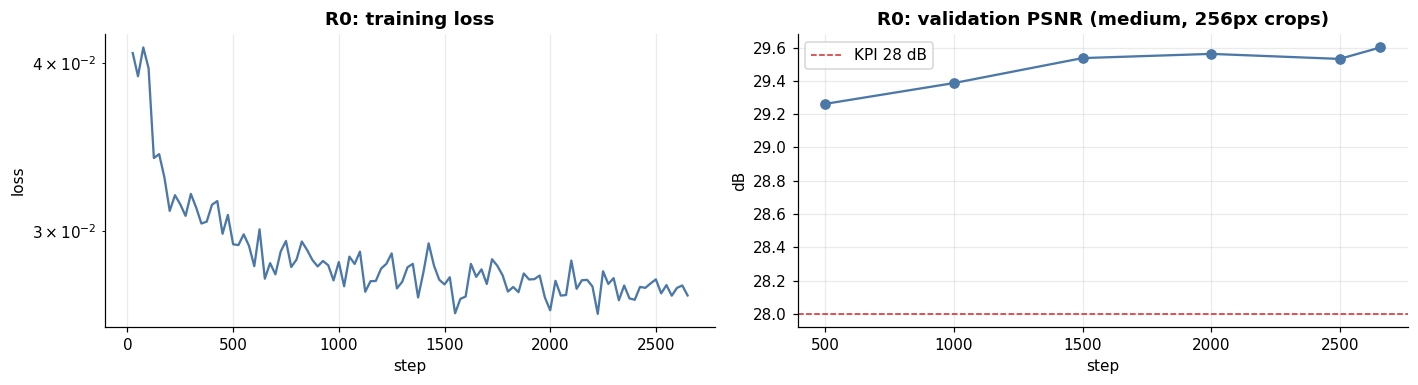

In [19]:
# ── 4.2  Train R0: pretrained ResNet-18 U-Net regression model ──────────────────
def r0_loss(model, lq, hr):
    return charbonnier(model(lq).float(), hr)


def r0_val(m):
    return val_psnr(lambda x: m(x))


R0, R0_hist = train_model("R0", R0Net(CFG.width), r0_loss, CFG.budgets["R0"], val_fn=r0_val)
print(f"R0 parameters: {count_params(R0):.2f} M")
plot_history(R0_hist, "R0")

[B0] finished checkpoint found (2296 steps, 7.0 min) - training skipped.
B0 parameters: 6.47 M | sampling: 25 DDIM steps


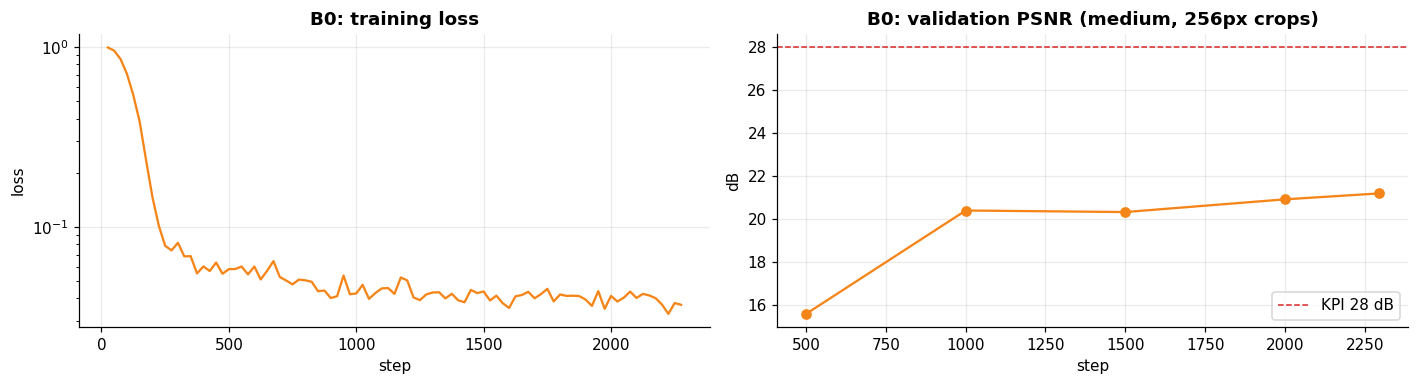

In [20]:
# ── 4.3  Train B0: SR3-style conditional DDPM (epsilon prediction) ──────────────
def b0_loss(model, lq, hr):
    x0, cond = hr * 2 - 1, lq * 2 - 1
    t = DIFF.sample_t(x0.shape[0])
    noise = torch.randn_like(x0)
    eps = model(torch.cat([DIFF.q_sample(x0, t, noise), cond], dim=1), t)
    return F.mse_loss(eps.float(), noise)


def b0_sample(model, lq01, noise, steps: int = CFG.b0_steps):
    """Restore a batch: DDIM from the given noise, conditioned on the degraded image. Returns [0, 1]."""
    cond = lq01 * 2 - 1
    with autocast():
        x0 = DIFF.ddim(lambda x, t: model(torch.cat([x, cond], dim=1), t), noise, steps, pred="eps", clip=1.0)
    return (x0 + 1) / 2


def b0_val(m):
    g = torch.Generator(device=DEVICE).manual_seed(CFG.seed)
    return val_psnr(lambda x: b0_sample(m, x, torch.randn(x.shape, generator=g, device=DEVICE)))


B0, B0_hist = train_model("B0", DiffusionUNet(6, width=CFG.width, mid_attn="global"), b0_loss,
                          CFG.budgets["B0"], val_fn=b0_val)
print(f"B0 parameters: {count_params(B0):.2f} M | sampling: {CFG.b0_steps} DDIM steps")
plot_history(B0_hist, "B0")

[Degraded] cached results loaded (100 images).
[R0] cached results loaded (100 images).
[B0] cached results loaded (100 images).


,images,psnr,ssim,lpips,psnr_y,ssim_y,latency_s,PSNR ≥ 28,SSIM ≥ 0.85,LPIPS ≤ 0.20
model,,,,,,,,,,
Degraded,100,27.11,0.6500,0.4331,28.83,0.7121,0.001,False,False,False
R0,100,30.27,0.8536,0.2035,32.24,0.8853,0.767,True,True,False
B0,100,19.16,0.6666,0.4131,21.31,0.7502,11.154,False,False,False


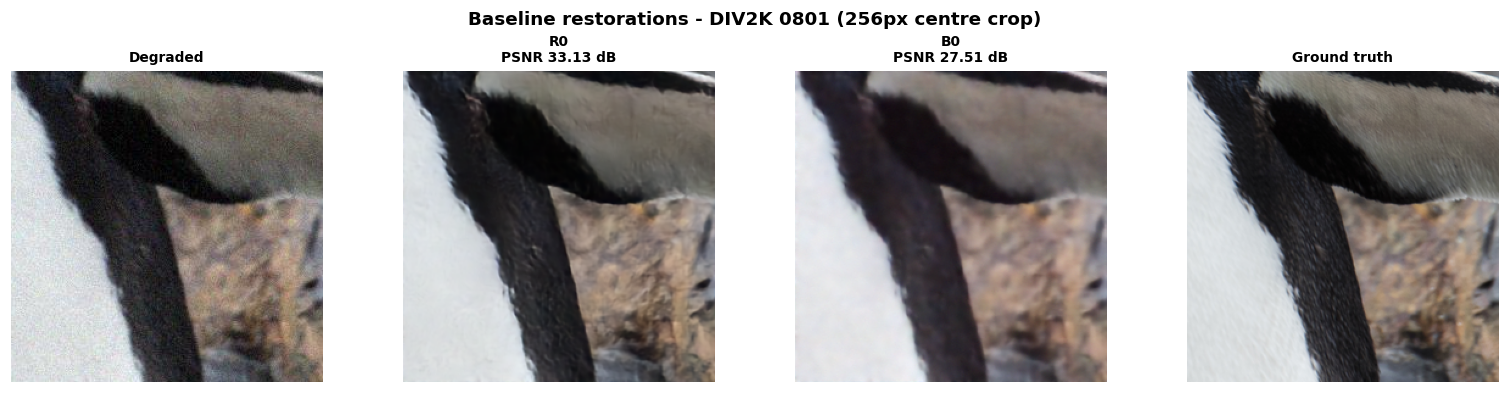

In [21]:
# ── 4.4  Evaluate the baselines on the full-resolution test set ─────────────────
restore_degraded = lambda lq, name="image": lq
restore_R0 = make_restorer(lambda x: R0(x))
restore_B0 = make_restorer(lambda x, n: b0_sample(B0, x, n), needs_noise=True)

R0.eval()
B0.eval()
with torch.no_grad():
    EVAL = {
        "Degraded": evaluate("Degraded", restore_degraded, n_samples=0),
        "R0": evaluate("R0", restore_R0),
        "B0": evaluate("B0", restore_B0),
    }

baseline = summarize(EVAL.values())
baseline.to_csv(DIRS["results"] / "baseline_results.csv")
display(style_summary(baseline, f"Baselines on {len(SPLITS['test'])} test images "
                                f"({'full resolution' if not CFG.eval_crop else f'{CFG.eval_crop}px crops'}, "
                                f"{preset_label(CFG.kpi_preset)})"))

# visual comparison on one test image (zoomed crop)
_n = SPLITS["test"][0]
_hr, _lq = load_test_pair(_n)
_crop = lambda im: center_crop(im, 256)
with torch.no_grad():
    _outs =[restore_R0(_crop(_lq), _n), restore_B0(_crop(_lq), _n)]
_ims = [_crop(_lq)] + _outs + [_crop(_hr)]
_titles = ["Degraded"] + [f"{m}\nPSNR {compute_metrics(o, _crop(_hr))['psnr']:.2f} dB" for m, o in zip(["R0", "B0"], _outs)] + ["Ground truth"]
show_images(_ims, _titles, size=3.6, suptitle=f"Baseline restorations - DIV2K {_n} (256px centre crop)",
            name="baselines_visual")

## 4.5 Reading the baseline results

- **Degraded row.** This is the input itself, so it shows how much each model improves on it. At `medium`, the input is below all three quality KPIs.
- **R0 (regression).** A single forward pass, with transfer learning from ImageNet, gives the highest PSNR per millisecond. Because it is trained with a pixel loss, it predicts the *average* plausible image: noise and JPEG blocks are removed well, but fine texture is smoothed. This normally shows up as an LPIPS that is good but not low enough, and it motivates the diffusion refinement in F1.
- **B0 (SR3-style diffusion).** B0 must generate the whole image from pure noise, so it has to learn image structure and restoration at the same time. With a ~7-minute T4 budget and 25 sampling steps, it typically trails R0 on PSNR and SSIM, and its latency is about 25 network evaluations per tile. This is the well-known cost of plain conditional diffusion (SR3, Palette) that the literature in §1.2 addresses.
- **What F1 must fix.** F1 (§5) keeps R0's strong, fast first estimate and uses diffusion only for the **residual** detail, with a hybrid CNN + Swin denoiser, v-prediction and only 4 DDIM steps. The aims are: LPIPS ≤ 0.20 while keeping PSNR ≥ 28 dB and SSIM ≥ 0.85, and a clear latency reduction (or ≥ 1 dB PSNR gain) over B0.

# 5. Final Model F1: Hybrid Residual Diffusion + Ablation Study *(Deliverable 4)*

## 5.1 Method

F1 combines the strengths of both baselines: R0's fast and accurate first estimate, and the diffusion model's ability to add realistic detail. Diffusion is used **only for the residual** that R0 could not recover.

```
                        ┌──────────────────────────────────────────────────────────────┐
 degraded y ──────────► │ R0  (ImageNet-pretrained ResNet-18 U-Net, frozen, 1 pass)    │──► x̂  first estimate
                        └───────────────┬──────────────────────────────────────────────┘
                                        │ encoder features (1/4 and 1/8 resolution)
                                        ▼
  τ · noise, τ ∈ [0,1] ► ┌──────────────────────────────────────────────────────────────┐
                         │ F1 denoiser: time-conditioned U-Net (v-prediction)           │
  inputs: [r_t, y, x̂] ─► │  • CNN ResBlocks at full and 1/2 resolution                  │ ─► v̂ → r̂₀
                         │  • Swin (shifted-window) Transformer blocks at 1/4, 1/8, mid │
                         │  • R0 features injected at 1/4 and 1/8 (zero-init 1×1 conv)  │
                         └──────────────────────────────────────────────────────────────┘
                                 repeated for 4 deterministic DDIM steps
                                        │
                                        ▼
                         restored x = x̂ + r̂₀ / (2 · s)
```

| Design choice | Why it helps | Expected effect |
|---|---|---|
| **Residual diffusion** (diffuse *x − x̂*, normalised by a scale *s* estimated once from data) | The residual is small and mostly high-frequency, so it is far easier to model than the whole image (as in Whang et al. 2022, ResShift) | Higher PSNR/SSIM than plain diffusion and very few steps needed |
| **v-prediction** (Salimans & Ho 2022) | The clean residual is recovered as r̂₀ = √ᾱ·r_t − √(1−ᾱ)·v̂, so at low noise it stays close to the input automatically and errors do not pile up over steps | Stable quality with few steps |
| **Sampling temperature τ**, chosen on the **validation set** | The starting noise is scaled by τ. τ = 1 draws a fully random sample, which roughly doubles the pixel error; smaller τ moves towards the most likely image | Controls the trade-off between perceptual quality (LPIPS) and fidelity (PSNR/SSIM) |
| **Transfer learning**: ImageNet-pretrained encoder (via R0) conditions the denoiser | Rich multi-scale features without training them from scratch | Faster convergence under a 10-minute budget |
| **Hybrid CNN + Swin** | Convolutions capture local texture; windowed attention captures repeated structure and long-range context at low cost | Sharper edges and textures |
| **Loss = Charbonnier + 0.1 · LPIPS** on the reconstructed image | The pixel term keeps PSNR/SSIM high; the perceptual term targets LPIPS | Meets the LPIPS KPI without sacrificing PSNR |
| **4-step DDIM** (vs 25 for B0) and a single R0 pass | Far fewer network evaluations per tile | Large latency reduction vs B0 |

**Development note.** A first version of F1 predicted the clean residual directly (x₀-prediction) and always sampled at τ = 1. It scored *below* R0, and got worse with more sampling steps and with longer training, because each step built on invented texture from the previous one and random sampling adds pixel error. That version is kept in `archive_x0pred/` and reported in ablation E.

Archived 30 files of the first F1 version (x0-prediction) to d:\5th sem Projects\DL COURSE PROJECT\I10_DIV2K\full_run\archive_x0pred
Residual scale s = 5.802 (R0 residual std in [-1, 1] units = 0.0862)


train F1:   7%|▋         | 500/7000 [03:19<31:16,  3.46it/s, loss=0.0265, min=2.4]

[F1] step   500 |  2.4 min | val PSNR 29.15 dB


train F1:   9%|▊         | 612/7000 [03:53<31:29,  3.38it/s, loss=0.0245, min=2.9]   

[F1] snapshot saved at step 612 (3.0 min) for the equal-budget ablation


train F1:  14%|█▍        | 1000/7000 [05:47<28:18,  3.53it/s, loss=0.0243, min=4.9]

... (3 outputs left out)

train F1:  29%|██▊       | 2000/7000 [10:38<23:46,  3.50it/s, loss=0.0231, min=9.7]

[F1] step  2000 |  9.7 min | val PSNR 29.35 dB


train F1:  29%|██▉       | 2058/7000 [10:55<26:14,  3.14it/s, loss=0.0224, min=10.0]


[F1] final val PSNR 29.35 dB
[F1] done: 2058 steps, 10.0 min training (10.9 min wall clock this session, stopped by time budget)
F1 denoiser parameters: 10.08 M (+ 14.75 M frozen R0) | sampling: 4 DDIM steps


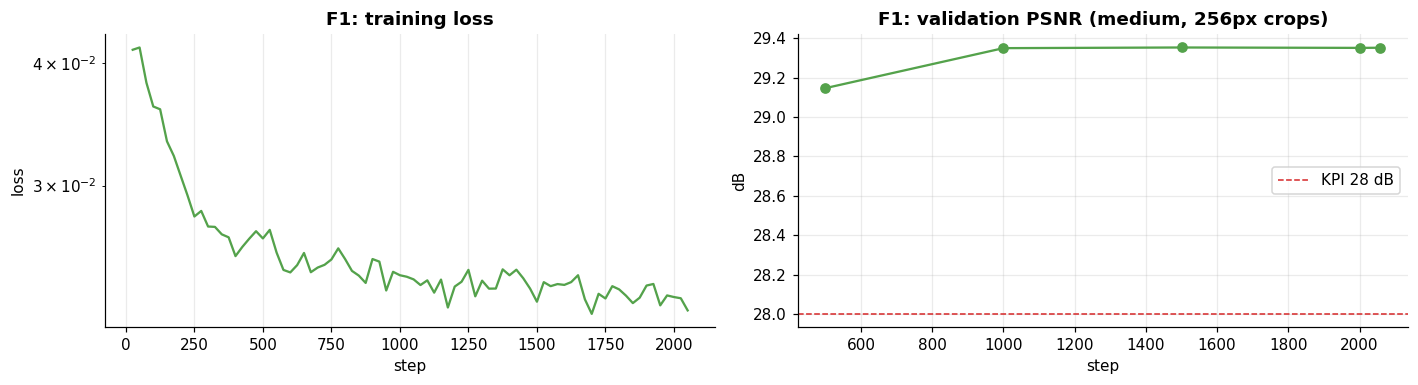

In [22]:
# ── 5.2  Build and train F1 (R0 frozen as first stage) ──────────────────────────
F1_COND = {2: 1, 3: 2}            # F1 U-Net level -> R0 encoder feature index (stride 4: 64 ch, stride 8: 128 ch)
F1_COND_CHS = {2: 64, 3: 128}
F1_METHOD = {"version": 2, "prediction": "v", "temperature": "selected on validation", "steps": CFG.f1_steps}
METHOD_FILE = DIRS["checkpoints"] / "F1_method.json"
ARCHIVE = RUN_DIR / "archive_x0pred"


def archive_first_attempt() -> None:
    """Move checkpoints/results of the first F1 version (x0-prediction) to archive_x0pred/ (kept for ablation E)."""
    if METHOD_FILE.exists() and json.loads(METHOD_FILE.read_text()).get("version") == F1_METHOD["version"]:
        return
    stale = [DIRS["checkpoints"] / f for f in ["F1.pt", "F1_snap.pt", "ABL_noSwin.pt", "ABL_noResidual.pt"]]
    stale += [DIRS["results"] / f for f in ["eval_F1.csv", "main_results.csv", "kpi_check.csv",
                                            "latency_benchmark.csv", "ablation_results.csv"]]
    stale += list(DIRS["results"].glob("eval_abl_F1_*.csv")) + list(DIRS["results"].glob("eval_abl_train_*.csv"))
    moved = 0
    for p in stale:
        if p.exists():
            dest = ARCHIVE / p.parent.name / p.name
            dest.parent.mkdir(parents=True, exist_ok=True)
            shutil.move(str(p), str(dest))
            moved += 1
    if (DIRS["samples"] / "F1").exists():
        dest = ARCHIVE / "samples" / "F1"
        if dest.exists():
            shutil.rmtree(dest)
        dest.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(DIRS["samples"] / "F1"), str(dest))
        moved += 1
    METHOD_FILE.write_text(json.dumps(F1_METHOD))
    if moved:
        print(f"Archived {moved} files of the first F1 version (x0-prediction) to {ARCHIVE}")


archive_first_attempt()

R0.eval()
for _p in R0.parameters():
    _p.requires_grad_(False)


@torch.no_grad()
def r0_first_stage(lq01: torch.Tensor):
    """First estimate x̂ in [0, 1] and the pretrained encoder features used as conditioning."""
    with autocast():
        xhat, feats = R0(lq01, return_feats=True)
    return xhat.float().clamp(0, 1), {lvl: feats[i] for lvl, i in F1_COND.items()}


RES_SCALE_FILE = DIRS["checkpoints"] / "F1_res_scale.json"
if RES_SCALE_FILE.exists():
    RES_SCALE = json.loads(RES_SCALE_FILE.read_text())["res_scale"]
else:                                              # scale so the training residual has std 0.5, like image data
    _stds, _loader = [], make_train_loader()
    for _, (_lq, _hr) in zip(range(20), _loader):
        _xhat, _ = r0_first_stage(_lq.to(DEVICE))
        _stds.append(((_hr.to(DEVICE) - _xhat) * 2).std().item())
    RES_SCALE = 0.5 / float(np.mean(_stds))
    RES_SCALE_FILE.write_text(json.dumps({"res_scale": RES_SCALE, "residual_std": float(np.mean(_stds))}))
    del _loader
print(f"Residual scale s = {RES_SCALE:.3f} (R0 residual std in [-1, 1] units = {0.5 / RES_SCALE:.4f})")

F1_TAU = 0.0                       # sampling temperature; replaced by the validation-selected value in 5.3


def v_noising(x0: torch.Tensor):
    """Sample t and noise; return x_t, sqrt(alpha_bar), sqrt(1 - alpha_bar) and t."""
    t = DIFF.sample_t(x0.shape[0])
    ab = DIFF._ab(t, x0)
    a, b = ab.sqrt(), (1 - ab).sqrt()
    return a * x0 + b * torch.randn_like(x0), a, b, t


def recon_loss(x_pred: torch.Tensor, hr: torch.Tensor) -> torch.Tensor:
    return charbonnier(x_pred, hr) + CFG.lpips_weight * get_lpips()(x_pred * 2 - 1, hr * 2 - 1).mean()


def f1_inputs(r_t, lq01, xhat):
    return torch.cat([r_t, lq01 * 2 - 1, xhat * 2 - 1], dim=1)


def f1_loss(model, lq, hr):
    """Residual diffusion with v-prediction; loss on the reconstructed image (pixel + perceptual)."""
    xhat, cond = r0_first_stage(lq)
    r_t, a, b, t = v_noising((hr - xhat) * 2 * RES_SCALE)
    v = model(f1_inputs(r_t, lq, xhat), t, cond).float()
    return recon_loss(xhat + (a * r_t - b * v) / (2 * RES_SCALE), hr)


def f1_sample(model, lq01, noise, steps: int | None = None, temperature: float | None = None):
    """R0 first stage + DDIM (v-prediction) over the residual, starting from temperature-scaled noise."""
    steps = steps or CFG.f1_steps
    tau = F1_TAU if temperature is None else temperature
    xhat, cond = r0_first_stage(lq01)
    with autocast():
        r0 = DIFF.ddim(lambda x, t: model(f1_inputs(x, lq01, xhat), t, cond), noise * tau, steps,
                       pred="v", clip=2 * RES_SCALE)
    return (xhat + r0 / (2 * RES_SCALE)).clamp(0, 1)


def make_val(sample_fn):
    """Validation PSNR during training (deterministic: temperature 0)."""
    def _val(m):
        g = torch.Generator(device=DEVICE).manual_seed(CFG.seed)
        return val_psnr(lambda x: sample_fn(m, x, torch.randn(x.shape, generator=g, device=DEVICE), temperature=0.0))
    return _val


def build_f1(swin: bool = True) -> DiffusionUNet:
    return DiffusionUNet(9, width=CFG.width, swin_levels=(2, 3) if swin else (),
                         mid_attn="swin" if swin else "none", cond_chs=F1_COND_CHS)


F1, F1_hist = train_model("F1", build_f1(), f1_loss, CFG.budgets["F1"], val_fn=make_val(f1_sample),
                          extra={"res_scale": RES_SCALE, **F1_METHOD},
                          snapshot_minutes=CFG.budgets["ABL"]["minutes"])
F1.eval()
print(f"F1 denoiser parameters: {count_params(F1):.2f} M (+ {count_params(R0):.2f} M frozen R0) | "
      f"sampling: {CFG.f1_steps} DDIM steps")
plot_history(F1_hist, "F1")

In [23]:
# ── 5.3  Choose the sampling temperature on the validation set ──────────────────
# Rule (fixed before looking at test data): among the candidate temperatures, take the one with the lowest
# validation LPIPS whose PSNR is within 0.25 dB of R0 and whose SSIM is within 0.003 of R0. If none
# qualifies, use tau = 0 (the most faithful setting).
TAU_FILE = DIRS["checkpoints"] / "F1_tau.json"


@torch.no_grad()
def val_quality(batch_fn) -> dict:
    """Mean PSNR / SSIM / LPIPS of batch_fn(lq01) over all validation crops."""
    rows = []
    for i in range(0, len(VAL_LQ), 8):
        lq = VAL_LQ[i:i + 8].to(DEVICE)
        with autocast():
            out = batch_fn(lq).float().clamp(0, 1)
        out = (out * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()
        hr = (VAL_HR[i:i + 8] * 255).round().byte().permute(0, 2, 3, 1).numpy()
        rows += [compute_metrics(o, h, with_y=False) for o, h in zip(out, hr)]
    return pd.DataFrame(rows).mean().to_dict()


if TAU_FILE.exists():
    tau_sel = json.loads(TAU_FILE.read_text())
else:
    r0q = val_quality(lambda x: R0(x))
    table = [{"setting": "R0", "tau": np.nan, **r0q}]
    for tau in CFG.f1_temperatures:
        g = torch.Generator(device=DEVICE).manual_seed(CFG.seed)
        q = val_quality(lambda x, tau=tau: f1_sample(F1, x, torch.randn(x.shape, generator=g, device=DEVICE),
                                                     temperature=tau))
        table.append({"setting": f"F1 τ={tau:g}", "tau": tau, **q})
    ok = [r for r in table[1:] if r["psnr"] >= r0q["psnr"] - 0.25 and r["ssim"] >= r0q["ssim"] - 0.003]
    best = min(ok, key=lambda r: r["lpips"]) if ok else table[1]
    tau_sel = {"tau": float(best["tau"]), "rule_satisfied": bool(ok), "table": table}
    TAU_FILE.write_text(json.dumps(tau_sel, indent=1, default=float))

F1_TAU = tau_sel["tau"]
display(pd.DataFrame(tau_sel["table"]).drop(columns="tau").set_index("setting").round(4).style
        .set_caption(f"Validation set ({len(VAL_LQ)} crops, {CFG.kpi_preset}): selected τ = {F1_TAU:g}"
                     + ("" if tau_sel["rule_satisfied"] else " (no τ met the rule; fallback τ = 0)")))

,psnr,ssim,lpips
setting,,,
R0,29.260000,0.821400,0.206100
F1 τ=0,28.987800,0.813300,0.214000
F1 τ=0.25,28.514100,0.788700,0.215300
F1 τ=0.5,27.825400,0.740500,0.203200
F1 τ=0.75,28.341100,0.772600,0.203900
F1 τ=1,27.992600,0.769600,0.164500


In [24]:
# ── 5.4  Full evaluation of F1 + KPI check (incl. fair latency benchmark) ───────
restore_F1 = make_restorer(lambda x, n: f1_sample(F1, x, n), needs_noise=True)
with torch.no_grad():
    EVAL["F1"] = evaluate("F1", restore_F1)

main = summarize(EVAL.values())
main.to_csv(DIRS["results"] / "main_results.csv")
display(style_summary(main, f"Main results on {len(SPLITS['test'])} test images "
                            f"({'full resolution' if not CFG.eval_crop else f'{CFG.eval_crop}px crops'}, "
                            f"{preset_label(CFG.kpi_preset)}) - F1: {CFG.f1_steps} steps, τ = {F1_TAU:g}"))


@torch.no_grad()
def benchmark_latency(restorers: dict, names: list) -> pd.DataFrame:
    """Time every model on the same images, pre-loaded in memory, after a warm-up on the first image."""
    pairs = {n: load_test_pair(n) for n in names}
    rows = []
    for model, fn in restorers.items():
        fn(pairs[names[0]][1], names[0])                               # warm-up at full size
        for n in names:
            with GpuTimer() as tm:
                fn(pairs[n][1], n)
            rows.append({"model": model, "image": n, "latency_s": tm.s})
    return pd.DataFrame(rows)


BENCH_CSV = DIRS["results"] / "latency_benchmark.csv"
bench_names = SPLITS["test"][:min(10, len(SPLITS["test"]))]
if BENCH_CSV.exists():
    bench = pd.read_csv(BENCH_CSV, dtype={"image": str})
else:
    bench = benchmark_latency({"R0": restore_R0, "B0": restore_B0, "F1": restore_F1}, bench_names)
    bench.to_csv(BENCH_CSV, index=False)
lat = bench.groupby("model")["latency_s"].agg(["mean", "std"])
display(lat.rename(columns={"mean": "latency mean (s)", "std": "latency std (s)"}).style.format("{:.3f}")
        .set_caption(f"Latency benchmark: same {len(bench_names)} images, warm GPU, {DEVICE.type.upper()}"))

f1_row, b0_row = main.loc["F1"], main.loc["B0"]
lat_red = 1 - lat.loc["F1", "mean"] / lat.loc["B0", "mean"]
psnr_gain = f1_row["psnr"] - b0_row["psnr"]
kpi = pd.DataFrame([
    ("PSNR (RGB)", f"≥ {CFG.kpi['psnr']} dB", f"{f1_row['psnr']:.2f} dB", f1_row["psnr"] >= CFG.kpi["psnr"]),
    ("SSIM (RGB)", f"≥ {CFG.kpi['ssim']}", f"{f1_row['ssim']:.4f}", f1_row["ssim"] >= CFG.kpi["ssim"]),
    ("LPIPS (AlexNet)", f"≤ {CFG.kpi['lpips']}", f"{f1_row['lpips']:.4f}", f1_row["lpips"] <= CFG.kpi["lpips"]),
    ("Latency reduction vs B0", f"≥ {CFG.kpi['latency_reduction']:.0%}", f"{lat_red:.1%}",
     lat_red >= CFG.kpi["latency_reduction"]),
    ("PSNR gain vs B0", f"≥ {CFG.kpi['psnr_gain']} dB", f"{psnr_gain:+.2f} dB", psnr_gain >= CFG.kpi["psnr_gain"]),
], columns=["KPI", "target", "F1 result", "pass"])
efficiency_ok = bool(kpi["pass"].iloc[3] or kpi["pass"].iloc[4])
kpi.loc[len(kpi)] = ("Efficiency KPI (either of the two above)", "one of them", "", efficiency_ok)
kpi["pass"] = kpi["pass"].map(lambda v: "PASS" if v else "FAIL")
kpi.to_csv(DIRS["results"] / "kpi_check.csv", index=False)
_col = lambda v: "background-color:#d4edda;color:#155724;font-weight:bold" if v == "PASS" else \
    "background-color:#f8d7da;color:#721c24;font-weight:bold"
_sty = kpi.style.hide(axis="index").set_caption("KPI check - final model F1")
display(_sty.map(_col, subset=["pass"]) if hasattr(_sty, "map") else _sty.applymap(_col, subset=["pass"]))
ALL_KPIS_PASS = (kpi["pass"].iloc[:3] == "PASS").all() and efficiency_ok
print("ALL KPIs MET" if ALL_KPIS_PASS else "Some KPIs not met - see the table above and the limitations in §8.")

,images,psnr,ssim,lpips,psnr_y,ssim_y,latency_s,PSNR ≥ 28,SSIM ≥ 0.85,LPIPS ≤ 0.20
model,,,,,,,,,,
Degraded,100,27.11,0.6500,0.4331,28.83,0.7121,0.001,False,False,False
R0,100,30.27,0.8536,0.2035,32.24,0.8853,0.767,True,True,False
B0,100,19.16,0.6666,0.4131,21.31,0.7502,11.154,False,False,False
F1,100,30.08,0.8480,0.2084,32.10,0.8808,2.601,True,False,False


,latency mean (s),latency std (s)
model,,
B0,10.919,0.957
F1,2.485,0.217
R0,0.216,0.020


KPI,target,F1 result,pass
PSNR (RGB),≥ 28.0 dB,30.08 dB,PASS
SSIM (RGB),≥ 0.85,0.8480,FAIL
LPIPS (AlexNet),≤ 0.2,0.2084,FAIL
Latency reduction vs B0,≥ 10%,77.2%,PASS
PSNR gain vs B0,≥ 1.0 dB,+10.93 dB,PASS
Efficiency KPI (either of the two above),one of them,,PASS


Some KPIs not met - see the table above and the limitations in §8.


[abl_B0_steps25] cached results loaded (20 images).


[abl_Degraded_blur_only] cached results loaded (20 images).
[abl_R0_blur_only] cached results loaded (20 images).


[abl_Degraded_noise_only] cached results loaded (20 images).
[abl_R0_noise_only] cached results loaded (20 images).


[abl_Degraded_jpeg_only] cached results loaded (20 images).
[abl_R0_jpeg_only] cached results loaded (20 images).


[abl_Degraded_moderate] cached results loaded (20 images).
[abl_R0_moderate] cached results loaded (20 images).


[abl_Degraded_medium] cached results loaded (20 images).
[abl_R0_medium] cached results loaded (20 images).


... (6 outputs left out)

[abl_Degraded_sigma50] cached results loaded (20 images).
[abl_R0_sigma50] cached results loaded (20 images).


[abl_R0_medium] cached results loaded (20 images).


,model,steps,psnr,ssim,lpips,psnr_y,ssim_y,latency_s
0,B0,25,20.553900,0.678300,0.348100,22.655100,0.752900,3.212600
1,F1,4,28.818000,0.830700,0.199200,30.757700,0.862300,0.718400
2,F1,8,28.827000,0.830800,0.197100,30.759800,0.862200,1.324300
3,F1,15,28.818900,0.830700,0.197300,30.754900,0.862100,2.419600
4,F1,25,28.816600,0.830700,0.197200,30.754800,0.862100,4.012700


,setting,tau,psnr,ssim,lpips,psnr_y,ssim_y,latency_s
0,R0 (regression),nan,29.022900,0.837600,0.190800,30.926100,0.868000,0.061000
1,F1 v-pred · τ=0,0.000000,28.818000,0.830700,0.199200,30.757700,0.862300,0.693100
2,F1 v-pred · τ=0.25,0.250000,28.587700,0.807200,0.196300,30.658100,0.855300,0.692300
3,F1 v-pred · τ=0.5,0.500000,28.130200,0.759100,0.173800,30.416100,0.836400,0.691300
4,F1 v-pred · τ=0.75,0.750000,28.512300,0.790100,0.173400,30.600000,0.845400,0.713200
5,F1 v-pred · τ=1,1.000000,27.922900,0.785500,0.157100,29.805700,0.823500,0.694000
6,F1 x₀-pred (first version) · τ=1 · 4 steps,1.000000,27.691700,0.774100,0.166900,29.550600,0.812700,0.736300
7,F1 x₀-pred (first version) · τ=1 · 8 steps,1.000000,26.203900,0.697100,0.251600,27.974300,0.741300,1.429600


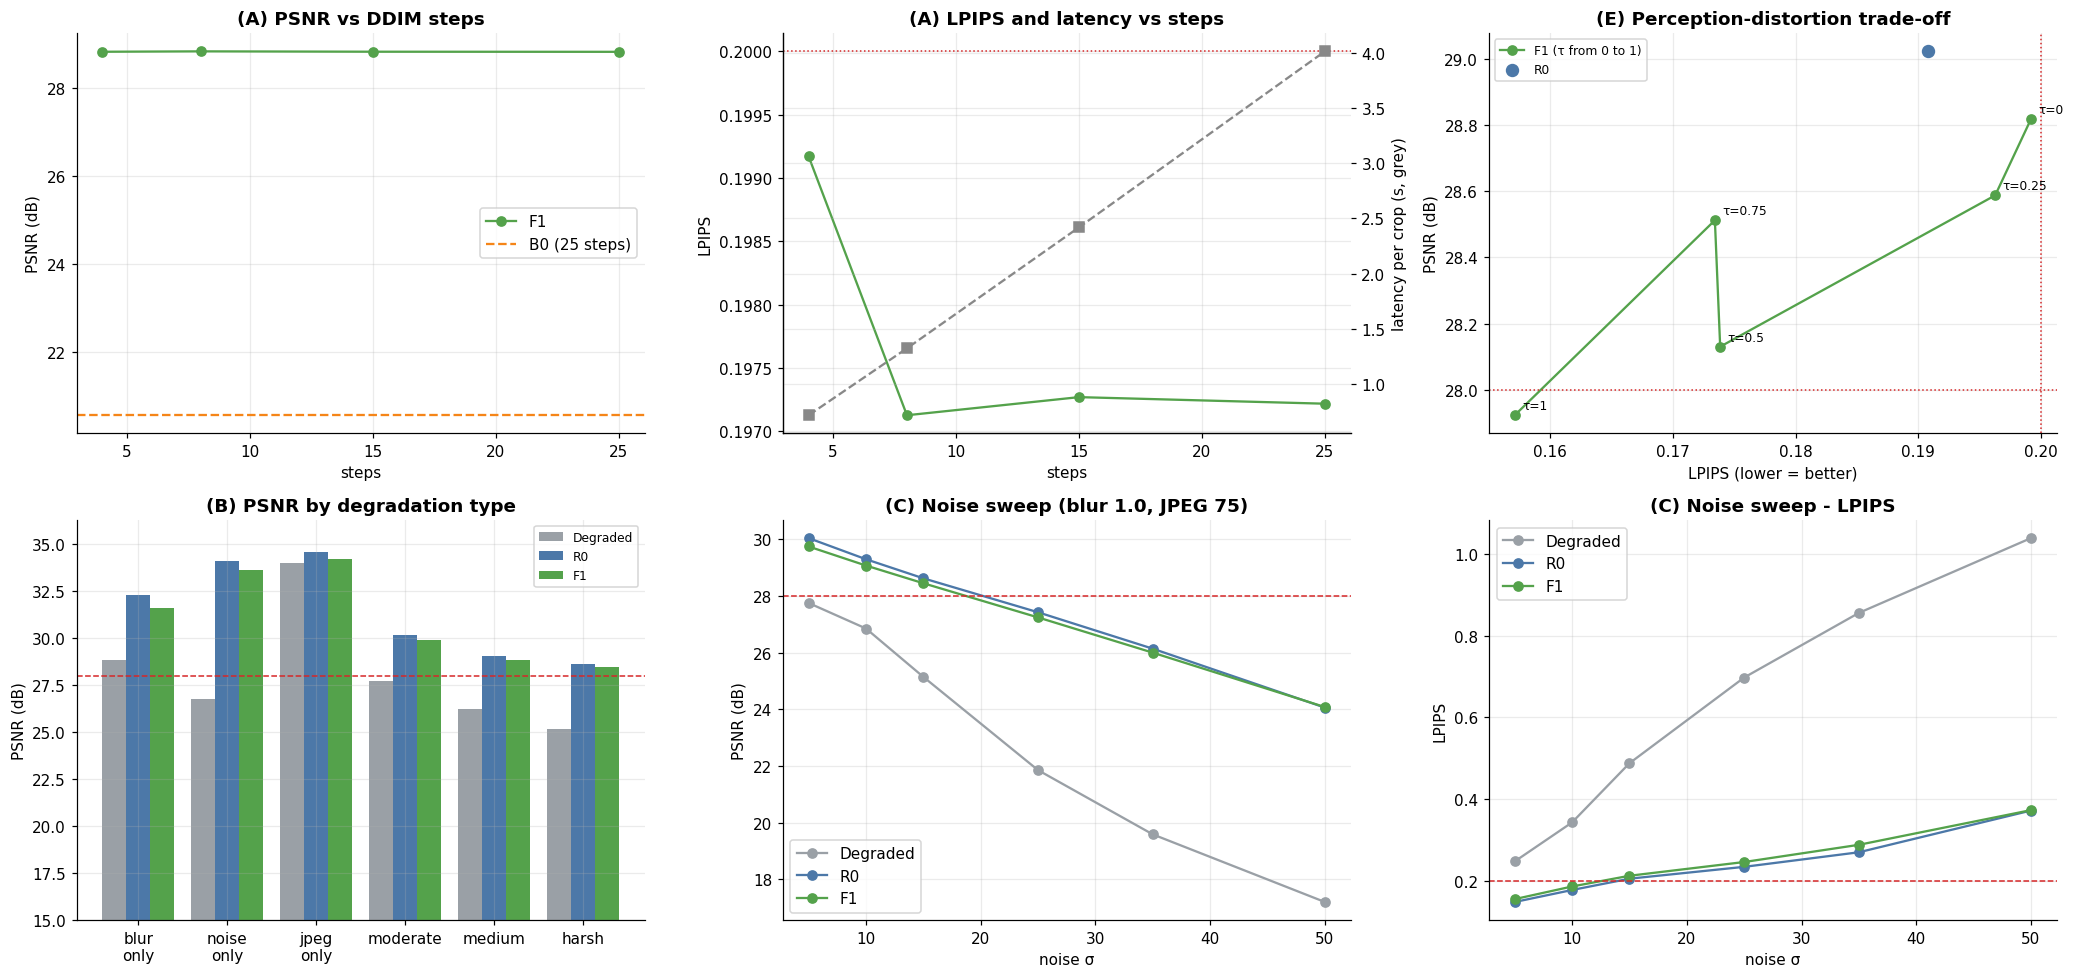

In [25]:
# ── 5.5  Inference-only ablations on the fixed 20-crop subset ───────────────────
ABL_IDX = {n: i for i, n in enumerate(ABL["names"])}
ABL_NAMES = ABL["names"]


def abl_pair(preset: str):
    return lambda n: (ABL["hr"][ABL_IDX[n]], ABL["lq"][preset][ABL_IDX[n]])


def run_eval(tag, fn, get_pair):
    with torch.no_grad():
        return evaluate(tag, fn, names=ABL_NAMES, get_pair=get_pair, n_samples=0)


def mean_row(df: pd.DataFrame, **labels) -> dict:
    return {**labels, **df[METRIC_COLS].mean().to_dict()}


# (A) number of DDIM sampling steps (at the selected temperature)
steps_rows = [mean_row(run_eval(f"abl_B0_steps{CFG.b0_steps}", restore_B0, abl_pair(CFG.kpi_preset)),
                       model="B0", steps=CFG.b0_steps)]
for s in CFG.ablation_steps:
    fn = make_restorer(lambda x, n, s=s: f1_sample(F1, x, n, steps=s), needs_noise=True)
    steps_rows.append(mean_row(run_eval(f"abl_F1_steps{s}", fn, abl_pair(CFG.kpi_preset)), model="F1", steps=s))
abl_steps = pd.DataFrame(steps_rows)

# (B) single vs combined degradations (including the harsh stress test)
deg_rows = []
for preset in CFG.eval_presets:
    for model, fn in [("Degraded", restore_degraded), ("R0", restore_R0), ("F1", restore_F1)]:
        deg_rows.append(mean_row(run_eval(f"abl_{model}_{preset}", fn, abl_pair(preset)), model=model, preset=preset))
abl_deg = pd.DataFrame(deg_rows)

# (C) noise-level sweep (blur 1.0 and JPEG 75 fixed, noise sigma varied)
sweep_rows = []
for sigma in CFG.noise_sweep:
    def _pair(n, sigma=sigma):
        hr = ABL["hr"][ABL_IDX[n]]
        return hr, degrade(hr, blur=1.0, noise=float(sigma), jpeg=75, rng=preset_rng(n, f"sweep{sigma}"))
    for model, fn in [("Degraded", restore_degraded), ("R0", restore_R0), ("F1", restore_F1)]:
        sweep_rows.append(mean_row(run_eval(f"abl_{model}_sigma{sigma}", fn, _pair), model=model, sigma=sigma))
abl_sweep = pd.DataFrame(sweep_rows)

# (E) sampling temperature = perception-distortion trade-off, plus the archived first F1 version
temp_rows = [mean_row(run_eval("abl_R0_medium", restore_R0, abl_pair(CFG.kpi_preset)), setting="R0 (regression)", tau=np.nan)]
for tau in CFG.f1_temperatures:
    fn = make_restorer(lambda x, n, tau=tau: f1_sample(F1, x, n, temperature=tau), needs_noise=True)
    temp_rows.append(mean_row(run_eval(f"abl_F1_tau{tau:g}", fn, abl_pair(CFG.kpi_preset)),
                              setting=f"F1 v-pred · τ={tau:g}", tau=tau))
for s in (4, 8):
    old = ARCHIVE / "results" / f"eval_abl_F1_steps{s}.csv"
    if old.exists():
        temp_rows.append(mean_row(pd.read_csv(old), setting=f"F1 x₀-pred (first version) · τ=1 · {s} steps", tau=1.0))
abl_temp = pd.DataFrame(temp_rows)

display(abl_steps.round(4).style.set_caption(f"(A) Sampling steps - {CFG.kpi_preset} preset, {len(ABL_NAMES)} crops, τ = {F1_TAU:g}"))
display(abl_deg.pivot(index="preset", columns="model", values=["psnr", "ssim", "lpips"])
        .reindex(list(CFG.eval_presets)).round(4).style.set_caption("(B) Single vs combined degradations"))
display(abl_temp.round(4).style.set_caption("(E) Sampling temperature and prediction target"))

fig, ax = plt.subplots(2, 3, figsize=(19, 9))
f1s = abl_steps[abl_steps["model"] == "F1"]
ax[0, 0].plot(f1s["steps"], f1s["psnr"], "o-", color=MODEL_COLORS["F1"], label="F1")
ax[0, 0].axhline(abl_steps.loc[abl_steps["model"] == "B0", "psnr"].iloc[0], color=MODEL_COLORS["B0"], ls="--",
                 label=f"B0 ({CFG.b0_steps} steps)")
ax[0, 0].set(title="(A) PSNR vs DDIM steps", xlabel="steps", ylabel="PSNR (dB)")
ax[0, 0].legend()
ax[0, 1].plot(f1s["steps"], f1s["lpips"], "o-", color=MODEL_COLORS["F1"])
_tw = ax[0, 1].twinx()
_tw.plot(f1s["steps"], f1s["latency_s"], "s--", color="#888888")
_tw.set_ylabel("latency per crop (s, grey)")
ax[0, 1].axhline(CFG.kpi["lpips"], color="#d62728", ls=":", lw=1)
ax[0, 1].set(title="(A) LPIPS and latency vs steps", xlabel="steps", ylabel="LPIPS")
vt = abl_temp[abl_temp["setting"].str.startswith("F1 v-pred")]
ax[0, 2].plot(vt["lpips"], vt["psnr"], "o-", color=MODEL_COLORS["F1"], label="F1 (τ from 0 to 1)")
for _, r in vt.iterrows():
    ax[0, 2].annotate(f"τ={r['tau']:g}", (r["lpips"], r["psnr"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
r0t = abl_temp.iloc[0]
ax[0, 2].scatter([r0t["lpips"]], [r0t["psnr"]], color=MODEL_COLORS["R0"], s=60, zorder=3, label="R0")
ax[0, 2].axvline(CFG.kpi["lpips"], color="#d62728", ls=":", lw=1)
ax[0, 2].axhline(CFG.kpi["psnr"], color="#d62728", ls=":", lw=1)
ax[0, 2].set(title="(E) Perception-distortion trade-off", xlabel="LPIPS (lower = better)", ylabel="PSNR (dB)")
ax[0, 2].legend(fontsize=8)
_w, _presets = 0.27, list(CFG.eval_presets)
for k, model in enumerate(["Degraded", "R0", "F1"]):
    v = abl_deg[abl_deg["model"] == model].set_index("preset").reindex(_presets)["psnr"]
    ax[1, 0].bar(np.arange(len(_presets)) + (k - 1) * _w, v, _w, label=model, color=MODEL_COLORS[model])
ax[1, 0].set_xticks(range(len(_presets)), [p.replace("_", "\n") for p in _presets])
ax[1, 0].axhline(CFG.kpi["psnr"], color="#d62728", ls="--", lw=1)
ax[1, 0].set(title="(B) PSNR by degradation type", ylabel="PSNR (dB)", ylim=(15, None))
ax[1, 0].legend(fontsize=8)
for model in ["Degraded", "R0", "F1"]:
    d = abl_sweep[abl_sweep["model"] == model]
    ax[1, 1].plot(d["sigma"], d["psnr"], "o-", color=MODEL_COLORS[model], label=model)
ax[1, 1].axhline(CFG.kpi["psnr"], color="#d62728", ls="--", lw=1)
ax[1, 1].set(title="(C) Noise sweep (blur 1.0, JPEG 75)", xlabel="noise σ", ylabel="PSNR (dB)")
ax[1, 1].legend()
for model in ["Degraded", "R0", "F1"]:
    d = abl_sweep[abl_sweep["model"] == model]
    ax[1, 2].plot(d["sigma"], d["lpips"], "o-", color=MODEL_COLORS[model], label=model)
ax[1, 2].axhline(CFG.kpi["lpips"], color="#d62728", ls="--", lw=1)
ax[1, 2].set(title="(C) Noise sweep - LPIPS", xlabel="noise σ", ylabel="LPIPS")
ax[1, 2].legend()
fig.tight_layout()
savefig(fig, "ablation_inference")
plt.show()

In [26]:
# ── 5.6  Retraining ablations at an equal training budget ───────────────────────
# Each variant gets exactly CFG.budgets["ABL"] minutes of training; F1 is represented by the snapshot saved
# after the same number of minutes. All variants use v-prediction, 4 steps and the selected temperature.
def plain_inputs(x_t, lq01):
    return torch.cat([x_t, lq01 * 2 - 1], dim=1)


def plain_loss(model, lq, hr):
    """No residual and no pretrained conditioning: diffuse the whole image (v-prediction, same loss as F1)."""
    x_t, a, b, t = v_noising(hr * 2 - 1)
    v = model(plain_inputs(x_t, lq), t).float()
    return recon_loss(((a * x_t - b * v) + 1) / 2, hr)


def plain_sample(model, lq01, noise, steps: int | None = None, temperature: float | None = None):
    steps = steps or CFG.f1_steps
    tau = F1_TAU if temperature is None else temperature
    with autocast():
        x0 = DIFF.ddim(lambda x, t: model(plain_inputs(x, lq01), t), noise * tau, steps, pred="v", clip=1.0)
    return ((x0 + 1) / 2).clamp(0, 1)


ABL_NO_SWIN, _ = train_model("ABL_noSwin", build_f1(swin=False), f1_loss, CFG.budgets["ABL"],
                             val_fn=make_val(f1_sample), extra={"res_scale": RES_SCALE})
ABL_NO_RES, _ = train_model("ABL_noResidual",
                            DiffusionUNet(6, width=CFG.width, swin_levels=(2, 3), mid_attn="swin"),
                            plain_loss, CFG.budgets["ABL"], val_fn=make_val(plain_sample))
ABL_NO_SWIN.eval()
ABL_NO_RES.eval()

F1_SNAP = build_f1().to(DEVICE).eval()
_snap = torch.load(DIRS["checkpoints"] / "F1_snap.pt", map_location=DEVICE, weights_only=False)
F1_SNAP.load_state_dict(_snap["ema"])
print(f"F1 snapshot: step {_snap['step']} after {_snap['elapsed'] / 60:.1f} min of training")

variants = {
    "F1 (full budget)": (lambda x, n: f1_sample(F1, x, n), count_params(F1)),
    "F1 (equal budget)": (lambda x, n: f1_sample(F1_SNAP, x, n), count_params(F1_SNAP)),
    "− Swin (CNN only)": (lambda x, n: f1_sample(ABL_NO_SWIN, x, n), count_params(ABL_NO_SWIN)),
    "− residual − pretrained cond.": (lambda x, n: plain_sample(ABL_NO_RES, x, n), count_params(ABL_NO_RES)),
}
train_rows = []
for label, (tensor_fn, params) in variants.items():
    tag = "abl_train_" + re.sub(r"[^A-Za-z0-9]+", "_", label).strip("_")
    df = run_eval(tag, make_restorer(tensor_fn, needs_noise=True), abl_pair(CFG.kpi_preset))
    train_rows.append(mean_row(df, variant=label, params_M=params))
abl_train = pd.DataFrame(train_rows)
display(abl_train.round(4).style.set_caption(
    f"(D) Component ablation - {CFG.kpi_preset} preset, {len(ABL_NAMES)} crops, "
    f"{CFG.budgets['ABL']['minutes']:g} min training each, τ = {F1_TAU:g}"))

train ABL_noSwin:  20%|██        | 500/2500 [01:52<07:23,  4.51it/s, loss=0.0253, min=1.9]

[ABL_noSwin] step   500 |  1.9 min | val PSNR 29.31 dB


train ABL_noSwin:  32%|███▏      | 809/2500 [03:00<06:18,  4.47it/s, loss=0.0237, min=3.0]


[ABL_noSwin] final val PSNR 29.29 dB
[ABL_noSwin] done: 809 steps, 3.0 min training (3.0 min wall clock this session, stopped by time budget)


train ABL_noResidual:  20%|██        | 500/2500 [02:07<08:17,  4.02it/s, loss=0.0682, min=2.1]

[ABL_noResidual] step   500 |  2.1 min | val PSNR 19.14 dB


train ABL_noResidual:  29%|██▉       | 724/2500 [03:03<07:28,  3.96it/s, loss=0.0603, min=2.9]


[ABL_noResidual] final val PSNR 20.16 dB
[ABL_noResidual] done: 724 steps, 3.0 min training (3.1 min wall clock this session, stopped by time budget)
F1 snapshot: step 612 after 3.0 min of training


,variant,params_M,psnr,ssim,lpips,psnr_y,ssim_y,latency_s
0,F1 (full budget),10.076200,28.818000,0.830700,0.199200,30.757700,0.862300,0.717800
1,F1 (equal budget),10.076200,28.837400,0.831200,0.190100,30.853900,0.865700,0.704900
2,− Swin (CNN only),6.355800,28.826300,0.831900,0.191900,30.827800,0.865000,0.521800
3,− residual − pretrained cond.,10.037600,20.189800,0.432900,0.544300,23.617900,0.541300,0.633700


In [27]:
# ── 5.7  Consolidated ablation table ────────────────────────────────────────────
ablation = pd.concat([
    abl_steps.assign(study="A: DDIM steps", setting=abl_steps["model"] + " · " + abl_steps["steps"].astype(str) + " steps"),
    abl_deg.assign(study="B: degradation type", setting=abl_deg["model"] + " · " + abl_deg["preset"]),
    abl_sweep.assign(study="C: noise sweep", setting=abl_sweep["model"] + " · σ=" + abl_sweep["sigma"].astype(str)),
    abl_train.assign(study="D: components (equal budget)", setting=abl_train["variant"]),
    abl_temp.assign(study="E: temperature & prediction target"),
], ignore_index=True)[["study", "setting", "psnr", "ssim", "lpips", "psnr_y", "ssim_y", "latency_s"]]
ablation.to_csv(DIRS["results"] / "ablation_results.csv", index=False)


def _best(s: pd.Series):
    out = [""] * len(s)
    if s.name not in ("psnr", "ssim", "lpips"):
        return out
    for _, idx in ablation.groupby("study").groups.items():
        sub = s.loc[idx]
        best = sub.idxmin() if s.name == "lpips" else sub.idxmax()
        out[s.index.get_loc(best)] = "font-weight:bold;background-color:#e8f4ea"
    return out


display(ablation.style.format({c: "{:.4f}" for c in ["ssim", "lpips", "ssim_y"]} |
                              {c: "{:.2f}" for c in ["psnr", "psnr_y"]} | {"latency_s": "{:.3f}"})
        .apply(_best).hide(axis="index")
        .set_caption("All ablations (best value per study in bold) - saved to results/ablation_results.csv"))

study,setting,psnr,ssim,lpips,psnr_y,ssim_y,latency_s
A: DDIM steps,B0 · 25 steps,20.55,0.6783,0.3481,22.66,0.7529,3.213
A: DDIM steps,F1 · 4 steps,28.82,0.8307,0.1992,30.76,0.8623,0.718
A: DDIM steps,F1 · 8 steps,28.83,0.8308,0.1971,30.76,0.8622,1.324
A: DDIM steps,F1 · 15 steps,28.82,0.8307,0.1973,30.75,0.8621,2.420
A: DDIM steps,F1 · 25 steps,28.82,0.8307,0.1972,30.75,0.8621,4.013
B: degradation type,Degraded · blur_only,28.84,0.8683,0.2404,30.23,0.8794,0.000
B: degradation type,R0 · blur_only,32.28,0.9232,0.1159,34.09,0.9371,0.061
B: degradation type,F1 · blur_only,31.59,0.9134,0.1230,33.40,0.9291,0.693
B: degradation type,Degraded · noise_only,26.77,0.6319,0.1912,31.53,0.7928,0.000
B: degradation type,R0 · noise_only,34.07,0.9293,0.0503,36.50,0.9517,0.056
